### Задача и данные

К моменту выписки хотим предсказать повторную госпитализацию в течение 30 дней. Одна строка соответствует одной госпитализации. Положительный класс обозначен меткой `<30`. `NO` означает отсутствие записи о повторной госпитализации в источнике

In [1]:
'''все необходимые импорты'''

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from pathlib import Path
from pyod.models.ecod import ECOD
from sklearn.neighbors import LocalOutlierFactor
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score)

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

In [2]:
'''загрузка данных'''
data_dir = Path("data/raw")
if not data_dir.is_dir():
    data_dir = Path("../data/raw")

encounters = pd.read_csv(
    data_dir / "diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
        "payer_code": "string",
    },)

mapping_rows = pd.read_csv(
    data_dir / "IDS_mapping.csv",
    header=None,
    names=["code", "description"],
    dtype="string",
    keep_default_na=False,)

is_section_header = mapping_rows["description"].eq("description")
mapping_rows["field"] = mapping_rows["code"].where(is_section_header).ffill()

is_code = mapping_rows["code"].str.fullmatch(r"\d+")
id_mapping = mapping_rows.loc[is_code, ["field", "code", "description"]].copy()
id_mapping["code"] = id_mapping["code"].astype(int)

In [3]:
'''первичный обзор'''

assert encounters["encounter_id"].is_unique
assert set(encounters["readmitted"]) == {"<30", ">30", "NO"}
assert not id_mapping.duplicated(["field", "code"]).any()

'''смотрим на размеры выборки по госпитализациям'''
print(pd.Series({
    "госпитализации": len(encounters),
    "пациенты": encounters["patient_nbr"].nunique(),
    "столбцы": encounters.shape[1]}, name="количество").to_frame().to_string())

'''смотрим на профили стобцов'''
preview_columns = [
    "encounter_id", "patient_nbr", "age",
    "time_in_hospital", "discharge_disposition_id", "readmitted"]
print()
print(encounters[preview_columns].head().to_string())

column_profile = pd.DataFrame({
    "тип": encounters.dtypes.astype(str),
    "уникальных значений": encounters.nunique(),
    "пропуски, %": (encounters.isna().mean() * 100).round(2)})


'''чекаем пропуски, и в какой процент по пропускам'''
print()
print(column_profile.sort_values("пропуски, %", ascending=False).to_string())
print()
print(id_mapping.query("field == 'discharge_disposition_id'").head().to_string())

                количество
госпитализации      101766
пациенты             71518
столбцы                 50

   encounter_id  patient_nbr      age  time_in_hospital  discharge_disposition_id readmitted
0       2278392      8222157   [0-10)                 1                        25         NO
1        149190     55629189  [10-20)                 3                         1        >30
2         64410     86047875  [20-30)                 2                         1         NO
3        500364     82442376  [30-40)                 2                         1         NO
4         16680     42519267  [40-50)                 1                         1         NO

                             тип  уникальных значений  пропуски, %
weight                       str                    9        96.86
medical_specialty            str                   72        49.08
payer_code                string                   17        39.56
race                         str                    5         2.

### Рабочая выборка и разбиение

#### смотрим на исходы выписки

In [4]:
## Повторная госпитализация по исходу выписки
discharge_labels = (
    id_mapping.loc[id_mapping["field"].eq("discharge_disposition_id")]
    .set_index("code")["description"].rename("исход выписки"))

target_order = ["<30", ">30", "NO"]
counts = pd.crosstab(
    encounters["discharge_disposition_id"],
    encounters["readmitted"]).reindex(columns=target_order, fill_value=0)

totals = counts.sum(axis=1)
shares = counts.div(totals, axis=0).mul(100).round(1).add_suffix(", %")

discharge_summary = (
    counts.assign(всего=totals)
    .join(shares)
    .join(discharge_labels)
    .sort_values("всего", ascending=False))

assert discharge_summary["всего"].sum() == len(encounters)
discharge_summary[
    ["исход выписки", "всего", "<30", "<30, %", ">30", ">30, %", "NO", "NO, %"]]

,исход выписки,всего,<30,"<30, %",>30,">30, %",NO,"NO, %"
discharge_disposition_id,,,,,,,,
1,Discharged to home,60234,5602,9.3,21517,35.7,33115,55.0
3,Discharged/transferred to SNF,13954,2046,14.7,4916,35.2,6992,50.1
6,Discharged/transferred to home with home healt...,12902,1638,12.7,5362,41.6,5902,45.7
18,NULL,3691,459,12.4,1027,27.8,2205,59.7
2,Discharged/transferred to another short term h...,2128,342,16.1,668,31.4,1118,52.5
22,Discharged/transferred to another rehab fac in...,1993,552,27.7,519,26.0,922,46.3
11,Expired,1642,0,0.0,0,0.0,1642,100.0
5,Discharged/transferred to another type of inpa...,1184,247,20.9,350,29.6,587,49.6
25,Not Mapped,989,92,9.3,376,38.0,521,52.7


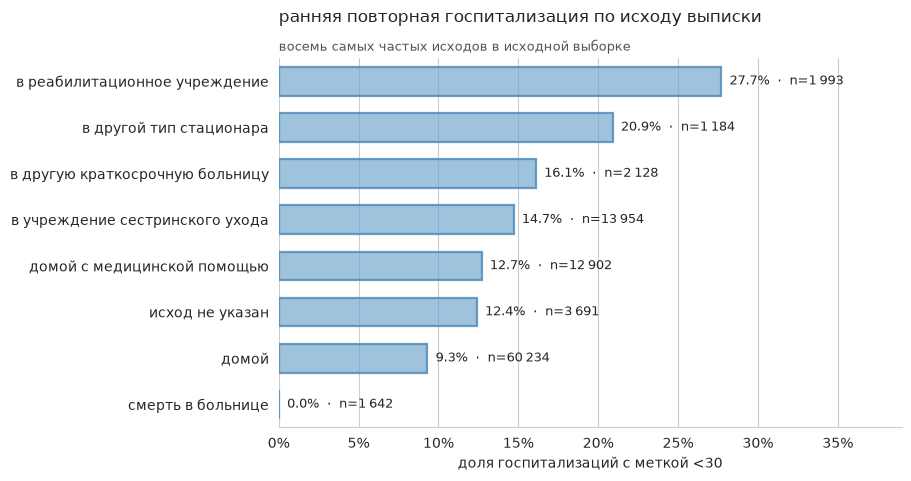

In [5]:
discharge_plot_labels = {
    1: "домой",
    2: "в другую краткосрочную больницу",
    3: "в учреждение сестринского ухода",
    5: "в другой тип стационара",
    6: "домой с медицинской помощью",
    11: "смерть в больнице",
    18: "исход не указан",
    22: "в реабилитационное учреждение",
}

discharge_plot = discharge_summary.head(8).sort_values("<30, %", ascending=False).copy()
discharge_plot["группа"] = (
    discharge_plot.index.to_series().map(discharge_plot_labels)
    .fillna(discharge_plot["исход выписки"])
)

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 4.7), layout="constrained")
    sns.barplot(
        data=discharge_plot, x="<30, %", y="группа",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{rate:.1f}%  ·  n={total:,}".replace(",", " ")
                for rate, total in zip(discharge_plot["<30, %"], discharge_plot["всего"])],
        padding=6,
        fontsize=9,
    )
    ax.set_xlim(0, 39)
    ax.set_xticks(range(0, 36, 5), labels=[f"{x}%" for x in range(0, 36, 5)])
    ax.set_title("ранняя повторная госпитализация по исходу выписки", loc="left", pad=26)
    ax.text(0, 1.02, "восемь самых частых исходов в исходной выборке",
            transform=ax.transAxes, color="#555555", fontsize=9)
    ax.set(xlabel="доля госпитализаций с меткой <30", ylabel=None)
    sns.despine(ax=ax, left=True)

plt.show()

**Вывод:** Доля ранних повторных госпитализаций различается по исходам выписки: 9,3% при выписке домой и 27,7% при переводе на реабилитацию. Для прогноза при выписке живого пациента предлагаем исключить коды смерти и отдельно проверить, как на результаты влияет включение выписок в хоспис.

In [6]:
'''собираем рабочую выборку'''

death_codes = {11, 19, 20, 21}
cohort = encounters.loc[
    ~encounters["discharge_disposition_id"].isin(death_codes)].copy()
cohort["readmitted_30d"] = cohort["readmitted"].eq("<30").astype(int)

print(pd.Series({
    "госпитализации": f"{len(cohort):,}",
    "пациенты": f"{cohort['patient_nbr'].nunique():,}",
    "доля ранних повторных госпитализаций": f"{cohort['readmitted_30d'].mean():.2%}"
}).to_frame("рабочая выборка").to_string())

                                     рабочая выборка
госпитализации                               100,114
пациенты                                      70,439
доля ранних повторных госпитализаций          11.34%


#### смотрим сколько госпитализаций приходится на пациента

пациенты с несколькими записями: 23.4%
доля строк этих пациентов: 46.1%


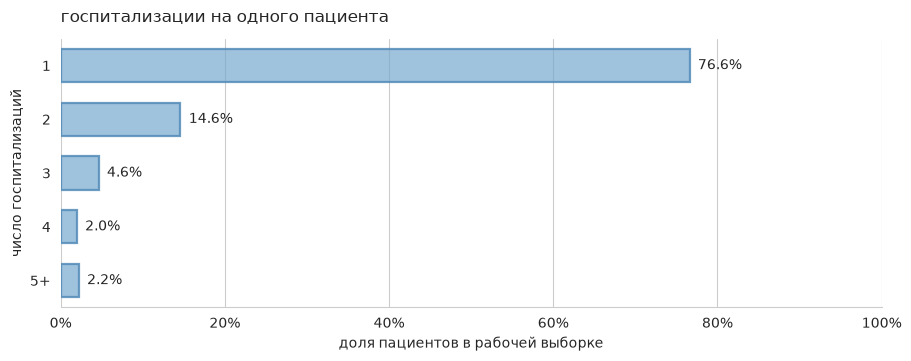

In [7]:
encounters_per_patient = cohort.groupby("patient_nbr").size()
repeat_patients = encounters_per_patient.gt(1)

print(f"пациенты с несколькими записями: {repeat_patients.mean():.1%}")
print(f"доля строк этих пациентов: {encounters_per_patient[repeat_patients].sum() / len(cohort):.1%}")

patient_counts = (
    encounters_per_patient.clip(upper=5)
    .value_counts().reindex(range(1, 6), fill_value=0))

patient_distribution = pd.DataFrame({
    "госпитализаций": ["1", "2", "3", "4", "5+"],
    "доля, %": patient_counts.to_numpy() / patient_counts.sum() * 100,
})

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    sns.barplot(
        data=patient_distribution, x="доля, %", y="госпитализаций",
        color="#76A9CFB3", saturation=1, edgecolor="#538BB9D9",
        linewidth=1.6, width=0.62, ax=ax,
    )
    for bar in ax.containers[0]:
        bar.set_facecolor("#76A9CFB3")

    ax.bar_label(
        ax.containers[0],
        labels=[f"{share:.1f}%" for share in patient_distribution["доля, %"]],
        padding=6,
    )
    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20), labels=[f"{x}%" for x in range(0, 101, 20)])
    ax.set_title("госпитализации на одного пациента", loc="left", pad=12)
    ax.set(xlabel="доля пациентов в рабочей выборке", ylabel="число госпитализаций")
    sns.despine(ax=ax, left=True)

plt.show()

#### Разбиение по пациентам

In [8]:
groups = cohort["patient_nbr"]
train_idx, holdout_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42).split(cohort, groups=groups)
)
train = cohort.iloc[train_idx].copy()
holdout = cohort.iloc[holdout_idx]
val_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    .split(holdout, groups=holdout["patient_nbr"])
)
validation = holdout.iloc[val_idx].copy()
test = holdout.iloc[test_idx].copy()

splits = {"Train": train, "Validation": validation, "Test": test}
assert sum(part["patient_nbr"].nunique() for part in splits.values()) == groups.nunique()
assert sum(len(part) for part in splits.values()) == len(cohort)

split_summary = pd.DataFrame({
    name: {
        "пациенты": part["patient_nbr"].nunique(),
        "госпитализации": len(part),
        "доля <30, %": 100 * part["readmitted_30d"].mean(),
    }
    for name, part in splits.items()
}).T
print(split_summary.to_string(formatters={
    "пациенты": "{:,.0f}".format, "госпитализации": "{:,.0f}".format,
    "доля <30, %": "{:.2f}".format,
}))

           пациенты госпитализации доля <30, %
Train        49,307         69,944       11.30
Validation   10,566         15,172       11.52
Test         10,566         14,998       11.35


### Гипотезы по данным

1. **Прошлые стационарные обращения связаны с долей ранних повторных госпитализаций.** Проверяем по возрасту, исходу выписки и с равным суммарным весом пациентов.
2. **Связь между измерением HbA1c и долей ранних повторных госпитализаций может различаться по основному диагнозу.** Сравниваем общие доли и доли внутри крупных групп ICD-9.
3. **Сводные признаки терапии частично повторяют детальные поля.** Сверяем `diabetesMed` с наличием препарата, а поле `change` сравниваем со статусами `Up` и `Down`.

### Исследование признаков

#### История обращений за предыдущий год

Гипотеза: доля ранних повторных госпитализаций выше у пациентов с предыдущими стационарными обращениями. Посмотрим, где возникает разница и насколько она зависит от пациентов с несколькими записями.

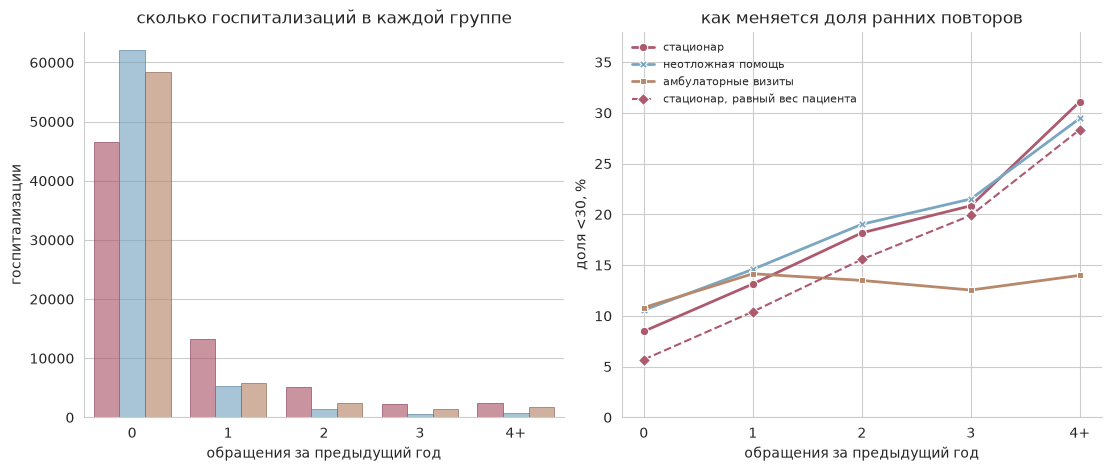

                      n  rate weighted_rate
number_inpatient                           
0                46,611  8.5%          5.7%
1                13,332 13.1%         10.4%
2                 5,187 18.2%         15.6%
3                 2,307 20.8%         19.9%
4+                2,507 31.1%         28.4%


In [9]:
visit_labels = {
    "number_inpatient": "стационар",
    "number_emergency": "неотложная помощь",
    "number_outpatient": "амбулаторные визиты",
}
visit_order = ["0", "1", "2", "3", "4+"]
patient_weight = 1 / train.groupby("patient_nbr")["patient_nbr"].transform("size")
visit_summary = {}


for column, title in visit_labels.items():
    visits = train[column].clip(upper=4).astype(str).replace("4", "4+")
    report = train["readmitted_30d"].groupby(visits).agg(n="size", rate="mean")
    report["weighted_rate"] = (
        (train["readmitted_30d"] * patient_weight).groupby(visits).sum()
        / patient_weight.groupby(visits).sum()
    )
    visit_summary[column] = report.reindex(visit_order)

visit_plot = pd.concat(
    {visit_labels[column]: report for column, report in visit_summary.items()},
    names=["вид обращения", "обращения"],
).reset_index()
visit_plot["доля <30, %"] = visit_plot["rate"] * 100
visit_colors = {
    "стационар": "#AD596E", "неотложная помощь": "#79A7C1",
    "амбулаторные визиты": "#B8886C",
}
inpatient = visit_summary["number_inpatient"]

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (volume_ax, rate_ax) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
    sns.barplot(
        data=visit_plot, x="обращения", y="n", hue="вид обращения",
        order=visit_order, hue_order=list(visit_colors), palette=visit_colors, alpha=0.65, saturation=1,
        linewidth=0.7, legend=False, ax=volume_ax,
    )
    for container, edge in zip(volume_ax.containers, ["#864056", "#567E99", "#8B624D"], strict=True):
        for bar in container:
            bar.set_edgecolor(edge)
    sns.lineplot(
        data=visit_plot, x="обращения", y="доля <30, %",
        hue="вид обращения", style="вид обращения", palette=visit_colors,
        markers=True, dashes=False, linewidth=2, ax=rate_ax,
    )
    sns.lineplot(x=visit_order, y=inpatient["weighted_rate"] * 100, color=visit_colors["стационар"],
                 linestyle="--", marker="D", label="стационар, равный вес пациента", ax=rate_ax)
    rate_ax.legend(title=None, loc="upper left", fontsize=8, frameon=False)
    volume_ax.set(title="сколько госпитализаций в каждой группе", ylabel="госпитализации")
    rate_ax.set(title="как меняется доля ранних повторов", ylabel="доля <30, %", ylim=(0, 38))
    for ax in (volume_ax, rate_ax):
        ax.set_xlabel("обращения за предыдущий год")
    sns.despine(fig=fig)
plt.show()

print(inpatient.to_string(formatters={"n": "{:,}".format, "rate": "{:.1%}".format,
                                     "weighted_rate": "{:.1%}".format}))

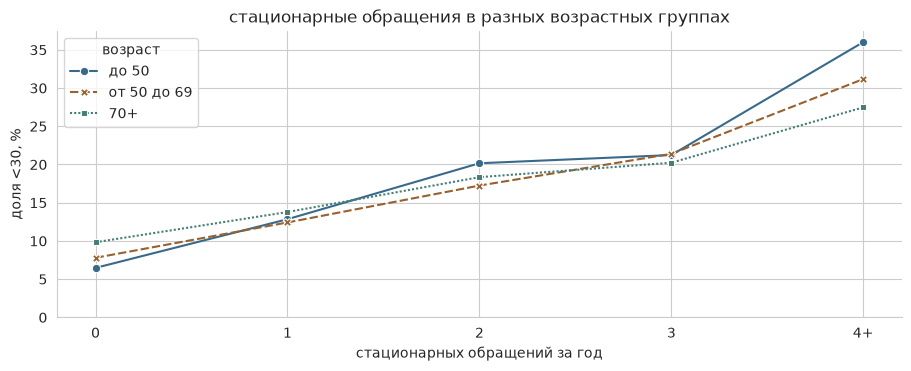

обращения        0     1     2     3   4+
возраст                                  
до 50         7523  1760   734   405  647
от 50 до 69  18610  5041  1972   874  972
70+          20478  6531  2481  1028  888


In [10]:
age_start = train["age"].str.extract(r"^\[(\d+)", expand=False).astype(int)
age_band = pd.cut(age_start, bins=[-1, 49, 69, 100], labels=["до 50", "от 50 до 69", "70+"])
inpatient_visits = train["number_inpatient"].clip(upper=4)
age_history = train["readmitted_30d"].groupby([
    age_band.rename("возраст"), inpatient_visits.rename("обращения"),
], observed=True).agg(n="size", rate="mean").reset_index()
age_history["доля <30, %"] = age_history["rate"] * 100

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
    sns.lineplot(
        data=age_history, x="обращения", y="доля <30, %",
        hue="возраст", style="возраст", markers=True,
        palette=["#386A8C", "#98612E", "#438074"], ax=ax,
    )
    ax.set_xticks(range(5), visit_order)
    ax.set(
        title="стационарные обращения в разных возрастных группах",
        xlabel="стационарных обращений за год", ylim=(0, None),
    )
    sns.despine(ax=ax)
plt.show()

print(age_history.pivot(index="возраст", columns="обращения", values="n").rename(columns={4: "4+"}).to_string())

**Вывод.** При 0 прошлых стационарных обращений доля `<30` составляет 8,5%, а при 4 и более достигает 31,1%. С равным суммарным весом пациентов рост сохраняется (от 5,7% до 28,4%). Для амбулаторных визитов монотонного роста по этим группам не видно. Рост от 0 до 4 и более обращений виден во всех трёх возрастных группах.

#### Прошлые госпитализации и исход выписки

Сохраняется ли связь с прошлыми стационарными обращениями внутри разных исходов выписки? Смотрим шесть самых частых расшифрованных исходов на `train`. В каждой ячейке показана доля `<30` среди госпитализаций с этим исходом выписки и таким числом прошлых обращений.

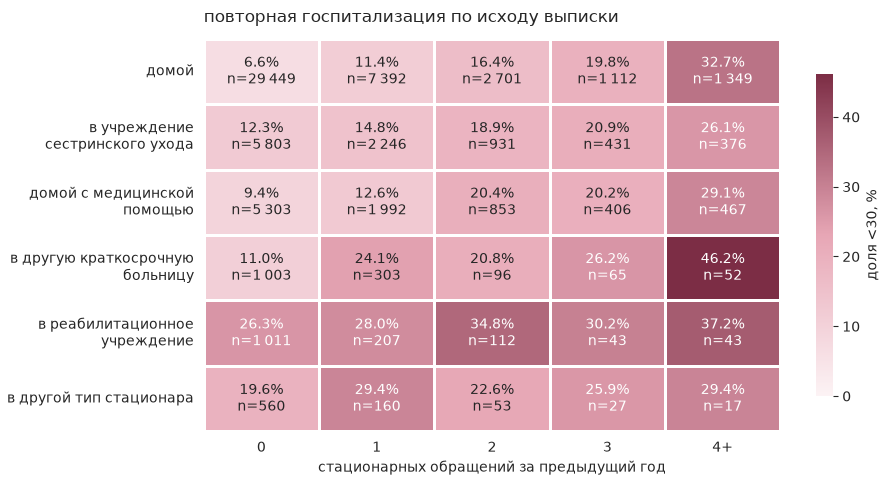

In [11]:
known_outcomes = [1, 2, 3, 5, 6, 22]
discharge_history = train.loc[train["discharge_disposition_id"].isin(known_outcomes)].copy()
outcome_order = discharge_history["discharge_disposition_id"].value_counts().index
discharge_history["прошлые обращения"] = (
    discharge_history["number_inpatient"].clip(upper=4).astype(str).replace("4", "4+")
)
discharge_history_stats = discharge_history.groupby(
    ["discharge_disposition_id", "прошлые обращения"]
)["readmitted_30d"].agg(n="size", rate="mean")
assert discharge_history_stats["n"].sum() == len(discharge_history)

history_counts = discharge_history_stats["n"].unstack().reindex(
    index=outcome_order, columns=visit_order
).fillna(0).astype(int)
history_rates = discharge_history_stats["rate"].unstack().reindex_like(history_counts) * 100
history_counts = history_counts.rename(index=discharge_plot_labels)
history_rates = history_rates.rename(index=discharge_plot_labels)
annotations = [
    [f"{rate:.1f}%\nn={n:,}".replace(",", " ") if n else ""
     for rate, n in zip(rate_row, count_row, strict=True)]
    for rate_row, count_row in zip(history_rates.to_numpy(), history_counts.to_numpy(), strict=True)
]

burgundy = sns.blend_palette(["#FCF3F5", "#E7A6B5", "#7C2D45"], as_cmap=True)
with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(10.6, 5.1))
    fig.subplots_adjust(left=0.29, right=0.97, bottom=0.13, top=0.9)
    sns.heatmap(
        history_rates, annot=annotations, fmt="", cmap=burgundy, vmin=0,
        linewidths=1, linecolor="white", annot_kws={"fontsize": 10},
        cbar_kws={"label": "доля <30, %", "shrink": 0.82}, ax=ax,
    )
    ax.set_title("повторная госпитализация по исходу выписки", loc="left", pad=12)
    ax.set(
        xlabel="стационарных обращений за предыдущий год", ylabel=None,
    )
    ax.set_yticks(ax.get_yticks(), [
        "в учреждение\nсестринского ухода" if code == 3
        else "в другую краткосрочную\nбольницу" if code == 2
        else "домой с медицинской\nпомощью" if code == 6
        else "в реабилитационное\nучреждение" if code == 22
        else discharge_plot_labels[code]
        for code in outcome_order
    ], rotation=0)
plt.show()

**Вывод.** Во всех шести исходах доля `<30` выше при 4 и более прошлых стационарных обращениях, чем при нуле. После выписки домой она растёт с 6,6% до 32,7%, а после перевода в учреждение сестринского ухода с 12,3% до 26,1%. Для переводов в другую краткосрочную больницу значение 46,2% основано на 52 госпитализациях.

#### Пропуски и измерение HbA1c

Отдельно сравниваем пропуски и категорию `None` в `A1Cresult`. Она означает, что HbA1c не измеряли.

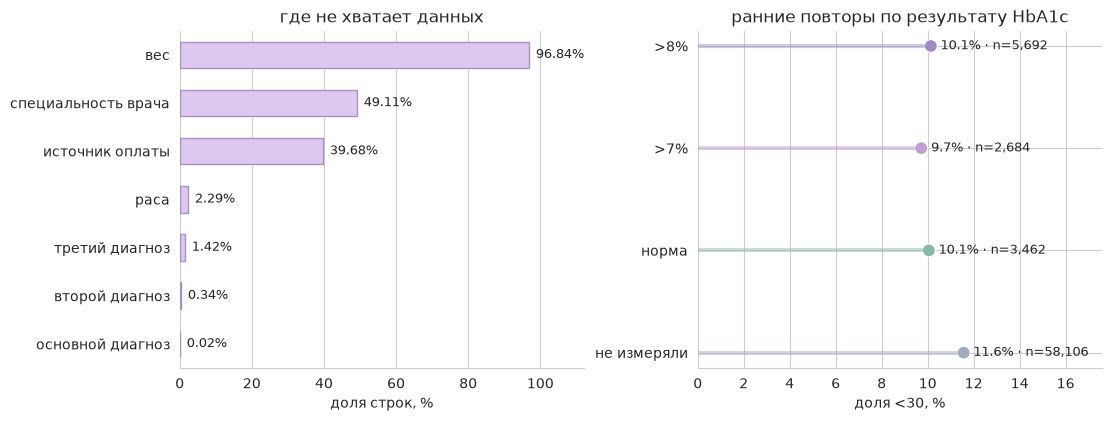

доля госпитализаций с измерением HbA1c на train: 16.9%.
                    n   rate
HbA1c измеряли              
False          58,106 11.57%
True           11,838 10.02%


In [12]:
missing_pct = (train.isna().mean() * 100).loc[lambda values: values > 0].sort_values(ascending=False)
a1c_order = ["None", "Norm", ">7", ">8"]
a1c_summary = (
    train.groupby("A1Cresult")["readmitted_30d"].agg(n="size", rate="mean").reindex(a1c_order)
)
measured = train["A1Cresult"].ne("None")
a1c_comparison = train.groupby(measured.rename("HbA1c измеряли"))["readmitted_30d"].agg(n="size", rate="mean")


field_labels = {
    "weight": "вес", "medical_specialty": "специальность врача",
    "payer_code": "источник оплаты", "race": "раса",
    "diag_1": "основной диагноз", "diag_2": "второй диагноз", "diag_3": "третий диагноз",
}
result_labels = ["не измеряли", "норма", ">7%", ">8%"]
result_colors = ["#9EACC2", "#87B7A8", "#C39DD0", "#A18AC5"]

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, (missing_ax, result_ax) = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
    sns.barplot(x=missing_pct, y=missing_pct.index.map(lambda field: field_labels.get(field, field)),
                color="#DDC9EF", saturation=1, edgecolor="#AA90C4", width=0.55, ax=missing_ax)
    missing_ax.bar_label(missing_ax.containers[0], fmt="%.2f%%", padding=5, fontsize=9)
    missing_ax.set(title="где не хватает данных", xlabel="доля строк, %", ylabel=None, xlim=(0, 112))

    rates = a1c_summary["rate"].to_numpy() * 100
    result_ax.hlines(result_labels, 0, rates, colors=result_colors, alpha=0.45, linewidth=3)
    sns.scatterplot(x=rates, y=result_labels, hue=result_labels, palette=result_colors,
                    legend=False, s=85, edgecolor="white", linewidth=0.8, ax=result_ax)
    for i, (n, rate) in enumerate(a1c_summary.itertuples(index=False)):
        result_ax.annotate(f"{rate:.1%} · n={n:,}", (rate * 100, i),
                           xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
    result_ax.invert_yaxis()
    result_ax.set(title="ранние повторы по результату HbA1c", xlabel="доля <30, %",
                  ylabel=None, xlim=(0, max(rates) + 6))
    sns.despine(fig=fig, left=True)
plt.show()

print(f"доля госпитализаций с измерением HbA1c на train: {measured.mean():.1%}.")
print(a1c_comparison.to_string(formatters={"n": "{:,}".format, "rate": "{:.2%}".format}))

**Вывод.** HbA1c измеряли в 16,9% госпитализаций на train. Доля `<30` составила 10,0% при измерении и 11,6% при его отсутствии. Направление различия совпадает с результатом статьи 2014 года, где выборку формировали по другим правилам. [Strack et al., 2014](https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/)

#### Доступность анализов по типу поступления

Сравниваем, какие результаты и сведения доступны к выписке. Коды `5`, `6` и `8` объединяем в «Не указан». Два редких типа, «Новорождённый» (`4`) и «Травматологический центр» (`7`), остаются в обучающей выборке и отдельно учтены под графиком.

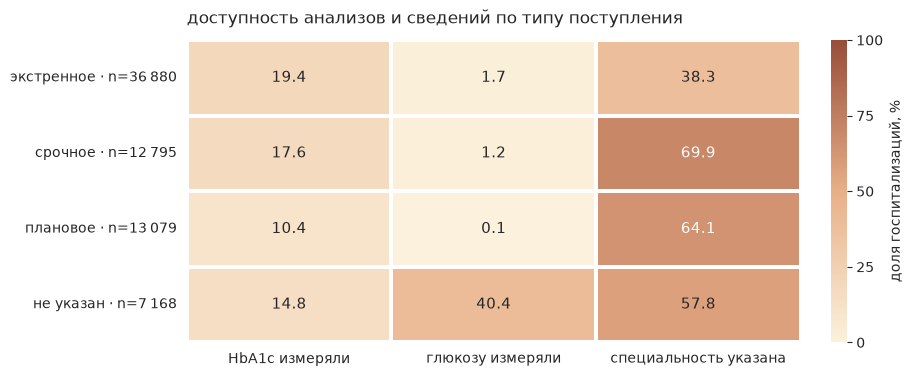

вне карты: новорождённые (8), травматологический центр (14).


In [13]:
admission_labels = {
    1: "экстренное", 2: "срочное", 3: "плановое",
    5: "не указан", 6: "не указан", 8: "не указан",
}
admission_type = train["admission_type_id"].map(admission_labels)
availability = pd.DataFrame({
    "HbA1c измеряли": train["A1Cresult"].notna() & train["A1Cresult"].ne("None"),
    "глюкозу измеряли": train["max_glu_serum"].notna() & train["max_glu_serum"].ne("None"),
    "специальность указана": train["medical_specialty"].notna(),
})
admission_order = ["экстренное", "срочное", "плановое", "не указан"]
admission_sizes = admission_type.value_counts().reindex(admission_order)
coverage_rates = availability.groupby(admission_type).mean().reindex(admission_order) * 100
excluded = train.loc[admission_type.isna(), "admission_type_id"].value_counts()
assert set(excluded.index) <= {4, 7}
assert admission_sizes.sum() + excluded.sum() == len(train)
assert coverage_rates.notna().to_numpy().all()

terracotta = sns.blend_palette(["#FBF1DC", "#E8AF88", "#984D38"], as_cmap=True)
with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(9, 3.65), layout="constrained")
    sns.heatmap(
        coverage_rates, annot=True, fmt=".1f", cmap=terracotta, vmin=0, vmax=100,
        linewidths=1.5, linecolor="white", annot_kws={"fontsize": 11},
        cbar_kws={"label": "доля госпитализаций, %", "ticks": [0, 25, 50, 75, 100]},
        ax=ax,
    )
    ax.set_title("доступность анализов и сведений по типу поступления", loc="left", pad=12)
    ax.set_ylabel(None)
    ax.set_yticks(ax.get_yticks(), [
        f"{group} · n={n:,}".replace(",", " ") for group, n in admission_sizes.items()
    ], rotation=0)
    ax.tick_params(axis="x", labelrotation=0)
plt.show()

print(f"вне карты: новорождённые ({excluded.get(4, 0)}), "
      f"травматологический центр ({excluded.get(7, 0)}).")


**Вывод.** При экстренном поступлении HbA1c измеряли чаще, чем при плановом (19,4% против 10,4%). Специальность врача указана в 38,3% экстренных и 69,9% срочных госпитализаций. В объединённой группе «Не указан» глюкозу измеряли в 40,4% случаев, но доли существенно различаются по исходным кодам: 57,3% для `5`, 28,0% для `6` и 0,0% для `8`. Поэтому для модели имеет смысл проверить эти коды по отдельности.

#### Источник поступления и служебные коды

Числовой код может стоять в строке, даже если сам источник поступления не указан. Сверяем наблюдаемые коды со справочником UCI на `train`.

In [14]:
source_labels = (
    id_mapping.loc[id_mapping["field"].eq("admission_source_id")]
    .set_index("code")["description"].str.strip().rename("описание")
)
source_audit = train.groupby("admission_source_id", dropna=False)["readmitted_30d"].agg(
    госпитализации="size", доля_ранних_повторов="mean",
).join(source_labels)
source_audit["доля в train"] = source_audit["госпитализации"] / len(train)

unknown_labels = {"null", "not available", "not mapped", "unknown/invalid"}
is_unknown = source_audit["описание"].str.casefold().isin(unknown_labels)
has_no_label = source_audit["описание"].isna()
assert source_audit["госпитализации"].sum() == len(train)
assert source_labels.index.is_unique

formatters = {"доля в train": "{:.2%}".format, "доля_ранних_повторов": "{:.2%}".format}
print(source_audit.sort_values("госпитализации", ascending=False).to_string(formatters=formatters))

unknown_count = source_audit.loc[is_unknown, "госпитализации"].sum()
unmapped_count = source_audit.loc[has_no_label, "госпитализации"].sum()
print(f"\nслужебные коды неизвестного источника: {unknown_count:,} ({unknown_count / len(train):.2%})")
print(f"строки без расшифровки в справочнике: {unmapped_count:,}")


                     госпитализации доля_ранних_повторов                                                   описание доля в train
admission_source_id                                                                                                             
7                             39213               11.81%                                             Emergency Room       56.06%
1                             20502               10.70%                                         Physician Referral       29.31%
17                             4698               10.94%                                                       NULL        6.72%
4                              2206                9.75%                                   Transfer from a hospital        3.15%
6                              1601                8.99%                 Transfer from another health care facility        2.29%
2                               776               10.82%                                         

**Вывод.** На train все наблюдаемые коды есть в справочнике. Служебные коды неизвестного источника встречаются в 4 891 госпитализации (6,99%). Почти все относятся к коду `17` (`NULL`): 4 698 строк. В первой модели сохраним числовые коды как отдельные категории. Редкие категории оценим по валидации.

#### Диагнозы по группам ICD-9

Сравниваем размер группы и долю `<30` по основному диагнозу. Для проверки охвата таблица показывает, как часто те же группы встречаются среди вторичных диагнозов.

In [15]:
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]
chapter_labels = [
    "инфекции", "новообразования", "эндокринные и обменные", "болезни крови",
    "психические расстройства", "нервная система и органы чувств", "кровообращение",
    "дыхательная система", "пищеварительная система", "мочеполовая система",
    "беременность и роды", "кожа", "опорно-двигательная система",
    "врождённые аномалии", "перинатальный период", "симптомы и признаки", "травмы и отравления",
]

def diagnosis_group(codes):
    prefix = pd.to_numeric(codes.str.extract(r"^(\d{3})", expand=False), errors="coerce")
    groups = pd.cut(
        prefix,
        bins=[0, 139, 239, 279, 289, 319, 389, 459, 519, 579, 629, 679, 709, 739, 759, 779, 799, 999],
        labels=chapter_labels,
    ).astype("string")
    groups = groups.mask(prefix.eq(250).fillna(False), "диабет (250.xx)")
    groups = groups.mask(codes.str.startswith(("E", "V"), na=False), "коды E и V")
    return groups.mask(codes.isna(), "пропуск").fillna("прочее")

diagnosis_groups = train[diagnosis_columns].apply(diagnosis_group)
assert diagnosis_group(pd.Series(["250.83", "042", "V45", pd.NA], dtype="string")).tolist() == [
    "диабет (250.xx)", "инфекции", "коды E и V", "пропуск",
]
diagnosis_coverage = diagnosis_groups.apply(pd.Series.value_counts).fillna(0).astype(int)
print(diagnosis_coverage.sort_values("diag_1", ascending=False).to_string())

primary = pd.DataFrame({
    "группа": diagnosis_groups["diag_1"],
    "код": train["diag_1"],
    "ранняя госпитализация": train["readmitted_30d"],
})
diagnosis_summary = primary.groupby("группа")["ранняя госпитализация"].agg(
    госпитализации="size", ранние="sum", доля="mean",
)
diagnosis_summary["частые коды"] = primary.groupby("группа")["код"].agg(
    lambda codes: ", ".join(codes.value_counts().head(3).index) or "нет кода"
)
diagnosis_summary["доля, %"] = diagnosis_summary["доля"] * 100

diagnosis_summary["логарифм размера"] = np.log10(diagnosis_summary["госпитализации"])
size_ticks = [1, 10, 100, 1_000, 10_000]

fig = px.scatter(
    diagnosis_summary.reset_index(), x="госпитализации", y="доля, %",
    hover_name="группа", hover_data={"ранние": True, "частые коды": True, "доля, %": ":.1f", "логарифм размера": False},
    color="логарифм размера",
    color_continuous_scale=["#F5DCE3", "#DC9BAD", "#B96279", "#7C2D45"],
    log_x=True, template="plotly_white",
    title="основной диагноз и ранняя повторная госпитализация",
    labels={"госпитализации": "госпитализации в группе (лог. шкала)", "доля, %": "доля <30, %"},
)
visible_size_ticks = [size for size in size_ticks
                      if diagnosis_summary["госпитализации"].min() <= size <= diagnosis_summary["госпитализации"].max()]
fig.update_coloraxes(colorbar={
    "title": "госпитализации", "tickvals": np.log10(visible_size_ticks),
    "ticktext": [f"{size:,}".replace(",", " ") for size in visible_size_ticks],
})
fig.update_traces(marker={"size": 12, "line": {"color": "#78374B", "width": 1.1}})
fig.show(renderer="plotly_mimetype")

                                 diag_1  diag_2  diag_3
кровообращение                    20782   21672   20569
дыхательная система                7073    6847    4594
пищеварительная система            6359    2734    2430
диабет (250.xx)                    6005    8959   11770
симптомы и признаки                5315    3197    3124
травмы и отравления                4813    1616    1333
мочеполовая система                3455    5484    4313
опорно-двигательная система        3450    1227    1358
новообразования                    2316    1724    1214
эндокринные и обменные             1851    5629    6328
кожа                               1791    2471    1707
прочее                             1709    1047    1047
психические расстройства           1564    1859    2171
коды E и V                         1197    1748    3542
нервная система и органы чувств     841     826    1195
болезни крови                       780    2026    1722
беременность и роды                 501     315 

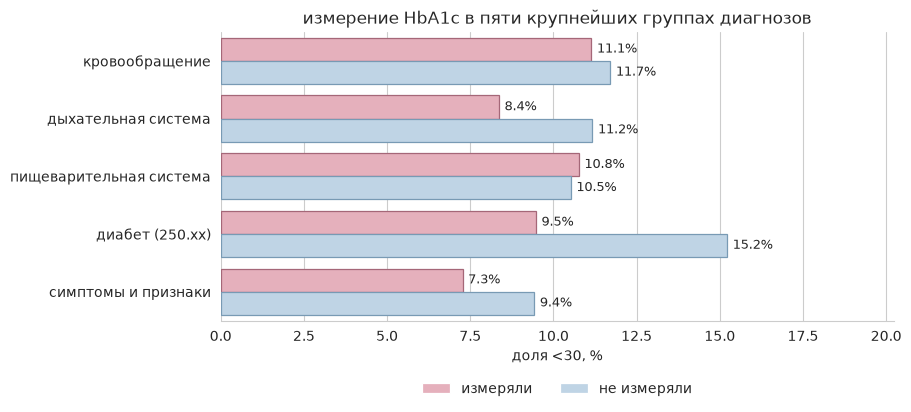

измерение                измеряли  не измеряли
группа                                        
диабет (250.xx)              1879         4126
дыхательная система          1148         5925
кровообращение               3671        17111
пищеварительная система       771         5588
симптомы и признаки          1018         4297


In [16]:
common_diagnoses = diagnosis_summary.nlargest(5, "госпитализации").index
a1c_by_diagnosis = (
    primary.assign(измерение=measured.map({True: "измеряли", False: "не измеряли"}))
    .loc[primary["группа"].isin(common_diagnoses)]
    .groupby(["группа", "измерение"])["ранняя госпитализация"].agg(n="size", rate="mean")
)
a1c_pairs = a1c_by_diagnosis.reset_index()
a1c_pairs["доля <30, %"] = a1c_pairs["rate"] * 100

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    sns.barplot(
        data=a1c_pairs, x="доля <30, %", y="группа", hue="измерение",
        order=common_diagnoses, hue_order=["измеряли", "не измеряли"], saturation=1,
        palette=["#E5B0BC", "#BFD4E5"], linewidth=0.9, ax=ax,
    )
    for container, edge in zip(ax.containers, ["#A56778", "#789AB4"], strict=True):
        for bar in container:
            bar.set_edgecolor(edge)
        ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=9)
    ax.set(
        title="измерение HbA1c в пяти крупнейших группах диагнозов",
        ylabel=None, xlim=(0, a1c_pairs["доля <30, %"].max() + 5),
    )
    ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    sns.despine(ax=ax, left=True)
plt.show()

print(a1c_by_diagnosis["n"].unstack().to_string())

**Вывод.** Для основного диагноза «Диабет» доля `<30` составила 9,5% при измерении HbA1c и 15,2% при его отсутствии. В группе болезней пищеварительной системы доли близки (10,8% и 10,5%). Такое сравнение описывает различия в данных и не оценивает эффект измерения.

#### Длительность госпитализации и объём помощи

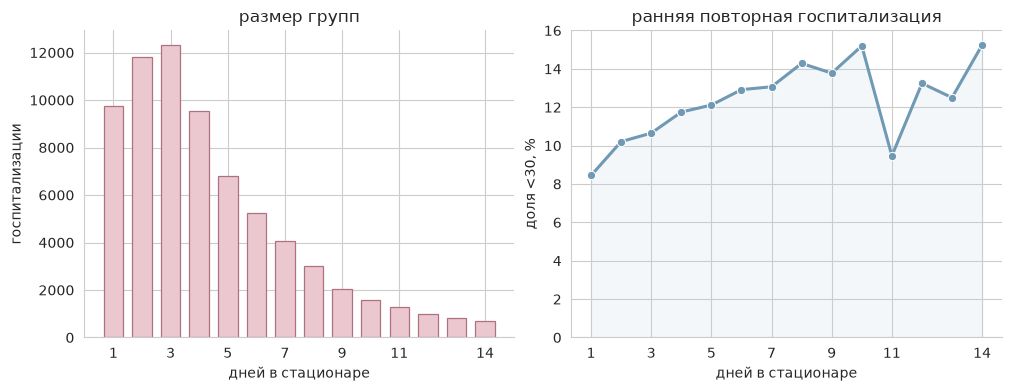

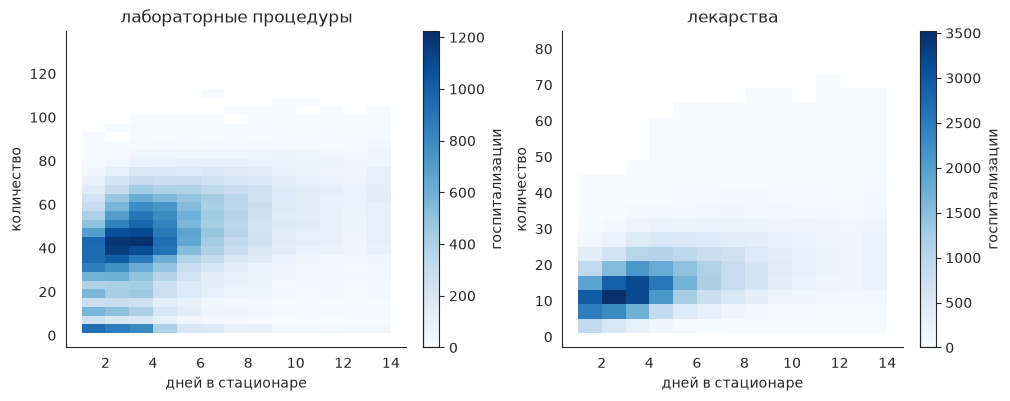

In [17]:
stay_summary = train.groupby("time_in_hospital")["readmitted_30d"].agg(n="size", rate="mean")

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (volume_ax, rate_ax) = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    days = stay_summary.index
    rates = stay_summary["rate"] * 100
    volume_ax.bar(days, stay_summary["n"], width=0.68, color="#EBC7D0",
                  edgecolor="#AF7180", linewidth=0.9)
    sns.lineplot(x=days, y=rates, color="#6F99B4", marker="o", linewidth=2.2, ax=rate_ax)
    rate_ax.fill_between(days, 0, rates, color="#BED5E5", alpha=0.17)
    volume_ax.set(title="размер групп", ylabel="госпитализации")
    rate_ax.set(title="ранняя повторная госпитализация", ylabel="доля <30, %", ylim=(0, None))
    for ax in (volume_ax, rate_ax):
        ax.set(xlabel="дней в стационаре", xticks=[1, 3, 5, 7, 9, 11, 14])
    sns.despine(fig=fig)
plt.show()

with sns.axes_style("white"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
    for ax, column, label in zip(
        axes, ["num_lab_procedures", "num_medications"], ["лабораторные процедуры", "лекарства"]
    ):
        sns.histplot(
            data=train, x="time_in_hospital", y=column, binwidth=(1, 4), pthresh=0,
            cmap="Blues", cbar=True, cbar_kws={"label": "госпитализации"}, ax=ax,
        )
        ax.set(title=label, xlabel="дней в стационаре", ylabel="количество")
    sns.despine(fig=fig)
plt.show()

**Вывод.** Доля `<30` растёт с 8,4% при однодневной госпитализации до 14,3% при восьмидневной. Для более длинных госпитализаций группы меньше, а доли колеблются. На двумерных гистограммах видно, что число анализов и лекарств стоит рассматривать вместе с длительностью пребывания.

#### Лекарства и изменения терапии

Какие препараты чаще всего отмечены в данных? Для инсулина и самого частого препарата среди остальных сравним долю `<30` по статусу терапии. Все графики этого блока построены по госпитализациям из `train`.

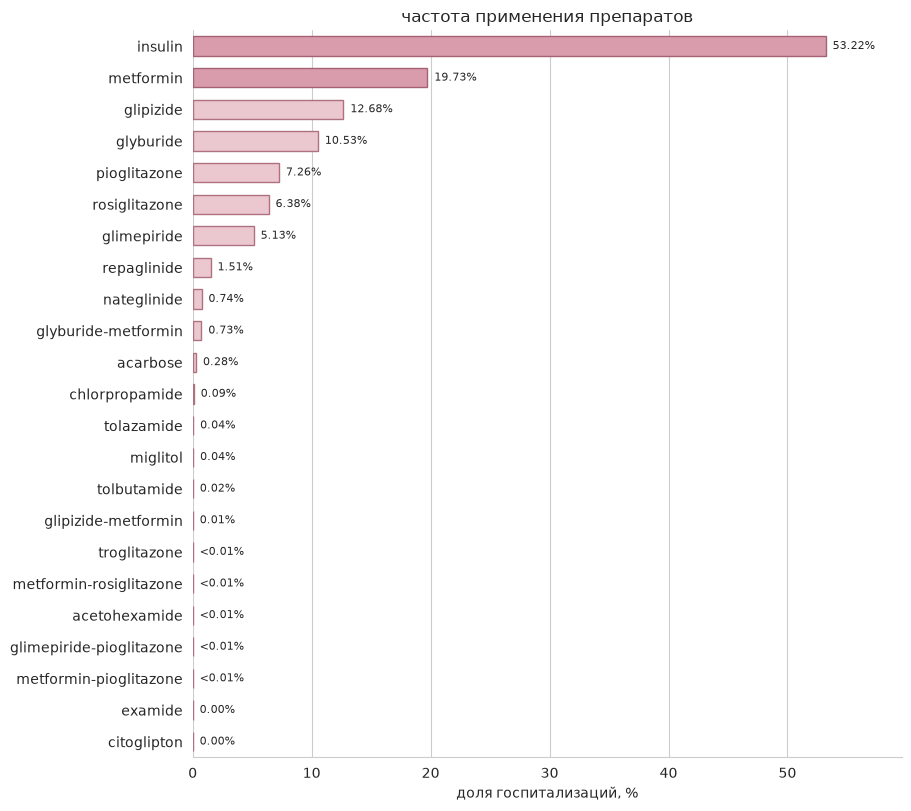

In [18]:
medications = train.loc[:, "metformin":"metformin-pioglitazone"]
med_status = ["No", "Steady", "Up", "Down"]
assert medications.isin(med_status).to_numpy().all()

med_frequency = medications.ne("No").mean().mul(100).sort_values(ascending=False, kind="stable")
med_choices = ["insulin", med_frequency.drop(index="insulin").idxmax()]

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
    sns.barplot(
        x=med_frequency, y=med_frequency.index, color="#EBC7D0",
        saturation=1, edgecolor="#AF7180", linewidth=1, width=0.61, ax=ax,
    )
    for drug, bar in zip(med_frequency.index, ax.containers[0], strict=True):
        if drug in med_choices:
            bar.set_facecolor("#D99CAC")
            bar.set_edgecolor("#A66275")
    ax.bar_label(
        ax.containers[0],
        labels=[f"{share:.2f}%" if share >= 0.01 or share == 0 else "<0.01%"
                for share in med_frequency],
        padding=5, fontsize=8,
    )
    ax.set(title="частота применения препаратов", xlabel="доля госпитализаций, %", ylabel=None)
    ax.margins(x=0.12)
    sns.despine(ax=ax, left=True)
plt.show()


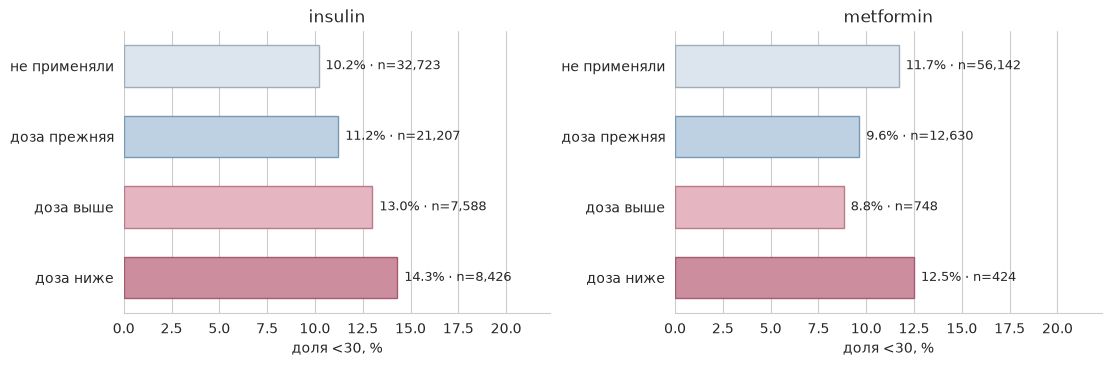

In [19]:
med_comparison = {
    drug: train.groupby(drug)["readmitted_30d"].agg(n="size", rate="mean")
    .reindex(med_status, fill_value=0)
    for drug in med_choices
}
status_labels = dict(zip(med_status, ["не применяли", "доза прежняя", "доза выше", "доза ниже"]))
status_fills = dict(zip(med_status, ["#DCE5ED", "#BDD1E2", "#E6B5C2", "#CC8D9E"]))
status_edges = dict(zip(med_status, ["#9EADBA", "#789AB4", "#B87B8B", "#A45C72"]))
max_rate = max(report["rate"].max() for report in med_comparison.values()) * 100

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.55), layout="constrained")
    for (drug, report), ax in zip(med_comparison.items(), axes, strict=True):
        shown = report.loc[report["n"].gt(0)]
        sns.barplot(
            x=shown["rate"] * 100, y=shown.index.map(status_labels),
            color="#EBC7D0", saturation=1, width=0.59, ax=ax,
        )
        for status, bar in zip(shown.index, ax.containers[0], strict=True):
            bar.set_facecolor(status_fills[status])
            bar.set_edgecolor(status_edges[status])
        ax.bar_label(ax.containers[0], padding=5, fontsize=9, labels=[
            f"{rate:.1%} · n={n:,}" for n, rate in shown.itertuples(index=False)
        ])
        ax.set(title=drug, xlabel="доля <30, %", ylabel=None, xlim=(0, max_rate + 8))
        sns.despine(ax=ax, left=True)
plt.show()


**Вывод.** Инсулин отмечен в 53,2% госпитализаций, метформин в 19,7%. Для инсулина доля `<30` составила 10,2% без применения и 14,3% при снижении дозы. Для метформина группы со сменой дозы заметно меньше. Эти доли описывают группы госпитализаций, и по ним нельзя оценить эффект изменения дозы.

#### Что отражают `diabetesMed` и `change`

Сверим `diabetesMed` с наличием хотя бы одного отмеченного препарата. Отдельно сравним `change` с повышением или снижением дозы хотя бы одного препарата. Поле `change` также может отражать смену препарата. [Описание признаков](https://pmc.ncbi.nlm.nih.gov/articles/PMC3996476/#tab1)

In [20]:
any_medication = medications.ne("No").any(axis=1)
any_dose_change = (medications.eq("Up") | medications.eq("Down")).any(axis=1)

med_flag_check = pd.crosstab(
    train["diabetesMed"], any_medication.map({False: "нет препарата", True: "есть препарат"})
)
change_flag_check = pd.crosstab(
    train["change"], any_dose_change.map({False: "нет Up/Down", True: "есть Up/Down"})
)
assert med_flag_check.to_numpy().sum() == change_flag_check.to_numpy().sum() == len(train)
print(med_flag_check.to_string(), end="\n\n")
print(change_flag_check.to_string())


col_0        есть препарат  нет препарата
diabetesMed                              
No                       0          16067
Yes                  53877              0

col_0   есть Up/Down  нет Up/Down
change                           
Ch             18935        13324
No                 0        37685


**Вывод.** На train `diabetesMed` полностью совпадает с наличием хотя бы одного препарата в детальных полях. Для `change` совпадение частичное: у 13 324 из 32 259 госпитализаций с `Ch` (41,3%) ни у одного препарата нет статуса `Up` или `Down`. Поле `change` стоит сохранить для отдельной проверки.

### Аномалии

#### Обучающая выборка и проверка значений

In [21]:
features = {"num_lab_procedures": "лабораторные процедуры", "num_medications": "лекарства"}
duration = "time_in_hospital"
values = train[[duration, *features]]
audit = pd.DataFrame({
    "пропуски": values.isna().sum(),
    "отрицательные": values.lt(0).sum(),
    "минимум": values.min(),
    "максимум": values.max(),
})
print(audit.to_string())
assert values.notna().all().all() and values.ge(0).all().all()
assert values[duration].between(1, 14).all()


                    пропуски  отрицательные  минимум  максимум
time_in_hospital           0              0        1        14
num_lab_procedures         0              0        1       132
num_medications            0              0        1        81


#### Общий порог и порог по длительности

Берём 99-й процентиль для каждого признака по всему `train` и отдельно для каждой длительности. Отмечаем значения строго выше порога. Из-за целочисленных значений и совпадений на границе доля отмеченных строк может отличаться от 1%.

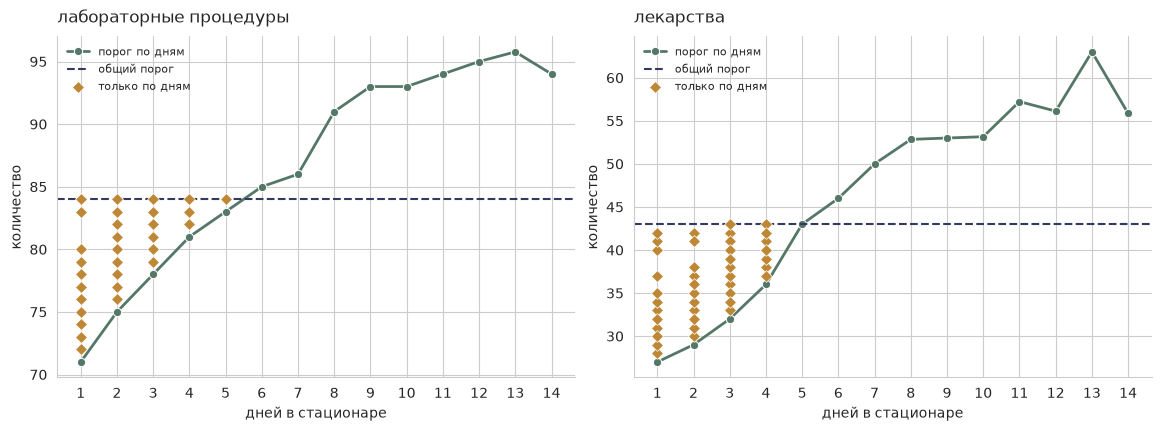

In [22]:
global_threshold = train[list(features)].quantile(0.99)
daily_threshold = train.groupby(duration)[list(features)].quantile(0.99)
daily_sizes = train[duration].value_counts().sort_index()
assert daily_sizes.sum() == len(train)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
    for (feature, label), ax in zip(features.items(), axes, strict=True):
        threshold = train[duration].map(daily_threshold[feature])
        only_context = train.loc[
            train[feature].gt(threshold) & train[feature].le(global_threshold[feature])
        ]
        sns.lineplot(x=daily_threshold.index, y=daily_threshold[feature], marker="o",
                     color="#557768", linewidth=2, label="порог по дням", ax=ax)
        ax.axhline(global_threshold[feature], color="#34395F", linestyle="--", label="общий порог")
        sns.scatterplot(data=only_context[[duration, feature]].drop_duplicates(),
                        x=duration, y=feature, marker="D", s=36, color="#BD8736",
                        label="только по дням", ax=ax, zorder=4)
        ax.set_title(label, loc="left", pad=10)
        ax.set(xlabel="дней в стационаре", ylabel="количество", xticks=daily_sizes.index)
        ax.legend(frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()


#### Какие госпитализации нашли правила

In [23]:
for feature, label in features.items():
    threshold = train[duration].map(daily_threshold[feature])
    above_global = train[feature].gt(global_threshold[feature])
    above_daily = train[feature].gt(threshold)
    flags = {
        "только общий порог": above_global & ~above_daily,
        "только порог по дням": above_daily & ~above_global,
        "оба порога": above_global & above_daily,
        "ни один порог": ~above_global & ~above_daily,
    }
    assert pd.DataFrame(flags).sum(axis=1).eq(1).all()
    print(label)
    summary = pd.DataFrame({
        group: {"строки": mask.sum(), "доля <30": train.loc[mask, "readmitted_30d"].mean()}
        for group, mask in flags.items()
    }).T
    print(summary.to_string(formatters={"строки": "{:.0f}".format, "доля <30": "{:.1%}".format}))

    examples = pd.concat([
        train.loc[mask, ["encounter_id", duration, feature, "readmitted"]]
        .assign(группа=group, порог_по_дням=threshold, строк_для_дня=train[duration].map(daily_sizes))
        .sort_values([feature, "encounter_id"], ascending=[False, True]).head(2)
        for group, mask in flags.items() if group != "ни один порог"
    ])

    display(examples.round({"порог_по_дням": 2}).reset_index(drop=True))


лабораторные процедуры
                     строки доля <30
только общий порог      316    13.3%
только порог по дням    314     8.6%
оба порога              336    11.9%
ни один порог         68978    11.3%


,encounter_id,time_in_hospital,num_lab_procedures,readmitted,группа,порог_по_дням,строк_для_дня
0,7111506,12,95,>30,только общий порог,95.00,989
1,34161666,12,95,>30,только общий порог,95.00,989
2,5293998,2,84,>30,только порог по дням,75.00,11793
3,12567660,3,84,<30,только порог по дням,78.00,12320
4,238167534,8,132,<30,оба порога,91.00,3017
5,52701030,13,129,>30,оба порога,95.77,824


лекарства
                     строки доля <30
только общий порог      357    13.7%
только порог по дням    306    10.5%
оба порога              304     9.5%
ни один порог         68977    11.3%


,encounter_id,time_in_hospital,num_medications,readmitted,группа,порог_по_дням,строк_для_дня
0,66619254,13,63,NO,только общий порог,63.00,824
1,300823706,13,63,NO,только общий порог,63.00,824
2,27777342,4,43,NO,только порог по дням,36.00,9542
3,28032552,4,43,NO,только порог по дням,36.00,9542
4,135412542,10,81,<30,оба порога,53.15,1586
5,137878980,12,79,NO,оба порога,56.12,989


**вывод.** Порог по длительности отметил дополнительно 314 госпитализаций по числу анализов и 306 по числу лекарств. Например, 84 анализа за два дня превышают порог для двух дней (75), но укладываются в общий порог (84). Точки на графике показывают уникальные сочетания длительности и количества.

#### Локальные аномалии и сравнение методов

#### Число соседей и совпадения на пороге

LOF сравнивает плотность вокруг госпитализации с плотностью вокруг её соседей. Используем семь числовых признаков из основного EDA. Масштабируем признаки на `train` через RobustScaler и сравниваем 15, 30 и 60 соседей. Основной вариант использует 30 соседей. Все методы отмечают по 1% строк. При одинаковых оценках используем один порядок строк с фиксированным seed.

In [24]:
anomaly_columns = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_inpatient", "number_emergency", "number_outpatient",
]
anomaly_features = train[anomaly_columns]
low, high = anomaly_features.quantile(0.01), anomaly_features.quantile(0.99)
span = (high - low).clip(lower=1)
quantile_score = pd.concat([
    (low - anomaly_features).div(span),
    (anomaly_features - high).div(span),
], axis=1).max(axis=1).clip(lower=0)

forest = IsolationForest(n_estimators=150, random_state=42, n_jobs=-1)
forest.fit(anomaly_features)
forest_score = pd.Series(-forest.score_samples(anomaly_features), index=train.index)

n_flagged = round(0.01 * len(train))
tie_order = train.sample(frac=1, random_state=42).index

assert anomaly_features.notna().all().all()
scaler = RobustScaler()
scaled_features = scaler.fit_transform(anomaly_features)
iqr = anomaly_features.quantile(0.75) - anomaly_features.quantile(0.25)
print("признаки с нулевым IQR (RobustScaler оставляет масштаб 1):",
      ", ".join(iqr.index[iqr.eq(0)]) or "нет")
print(f"строк с повторяющимся набором признаков: {anomaly_features.duplicated(keep=False).sum():,}")

lof_scores = {}
for neighbors in (15, 30, 60):
    lof = LocalOutlierFactor(n_neighbors=neighbors, n_jobs=-1)
    lof.fit_predict(scaled_features)
    lof_scores[neighbors] = pd.Series(-lof.negative_outlier_factor_, index=train.index)

def top_rows(score):
    return score.reindex(tie_order).nlargest(n_flagged).index

lof_top = {neighbors: top_rows(score) for neighbors, score in lof_scores.items()}
sensitivity = []
for neighbors, score in lof_scores.items():
    selected = lof_top[neighbors]
    cutoff = score.loc[selected].min()
    sensitivity.append({
        "соседей": neighbors,
        "совпали с LOF 30": len(selected.intersection(lof_top[30])),
        "строк с баллом на границе": score.eq(cutoff).sum(),
        "из них в топе": score.loc[selected].eq(cutoff).sum(),
    })
print(pd.DataFrame(sensitivity).to_string(index=False))


признаки с нулевым IQR (RobustScaler оставляет масштаб 1): number_emergency, number_outpatient
строк с повторяющимся набором признаков: 22,590


/Users/flexonafft/cu-ml-diabetes-project/.venv/lib/python3.14/site-packages/sklearn/neighbors/_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


 соседей  совпали с LOF 30  строк с баллом на границе  из них в топе
      15               429                          1              1
      30               699                          1              1
      60               501                          1              1


#### Пересечения и примеры, найденные только LOF

                                   строки доля_ранних_повторов
методы                                                        
LOF                                   596                11.4%
квантили                              362                22.4%
Isolation Forest                      326                27.0%
квантили + Isolation Forest           283                30.7%
Isolation Forest + LOF                 49                16.3%
квантили + Isolation Forest + LOF      41                24.4%
квантили + LOF                         13                23.1%


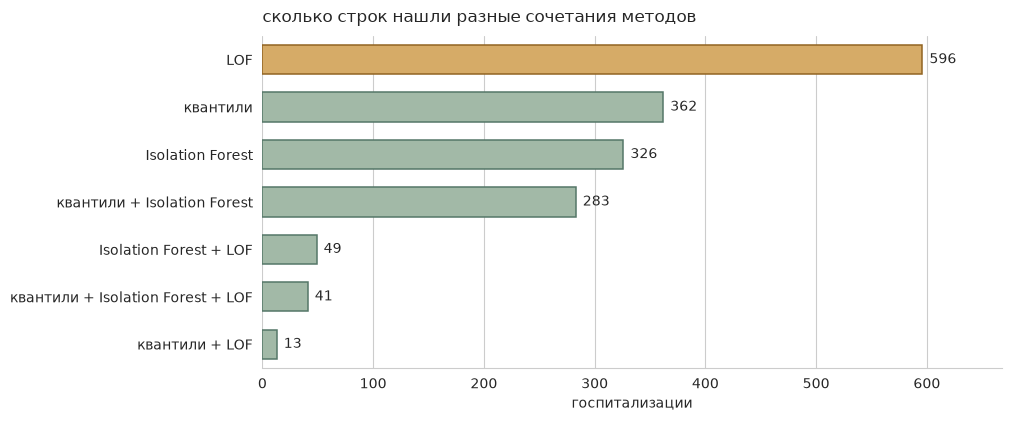

только LOF, без превышения порогов по дням: 423


,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_inpatient,number_emergency,number_outpatient,readmitted,порог по дням: num_lab_procedures,порог по дням: num_medications
0,273908820,1,58,6,4,0,1,0,NO,71.0,27.00
1,108766590,3,1,3,16,0,1,1,NO,78.0,32.00
2,287063994,1,1,6,18,0,1,0,NO,71.0,27.00
3,287591022,5,78,6,32,0,0,1,NO,83.0,43.00
4,112834596,1,29,6,13,0,1,0,NO,71.0,27.00
5,211832376,14,51,0,13,0,1,0,>30,94.0,55.86


In [25]:
selected_by = {
    "квантили": top_rows(quantile_score),
    "Isolation Forest": top_rows(forest_score),
    "LOF": lof_top[30],
}
flags = pd.DataFrame(
    {method: train.index.isin(rows) for method, rows in selected_by.items()},
    index=train.index,
)
assert flags.sum().eq(n_flagged).all()
intersection = flags.loc[flags.any(axis=1)].apply(
    lambda row: " + ".join(row.index[row]), axis=1,
).rename("методы")
overlap = train.loc[intersection.index, "readmitted_30d"].groupby(intersection).agg(
    строки="size", доля_ранних_повторов="mean",
).sort_values("строки", ascending=False)
assert overlap["строки"].sum() == flags.any(axis=1).sum()
print(overlap.to_string(formatters={"доля_ранних_повторов": "{:.1%}".format}))

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(10, 4.1), layout="constrained")
    sns.barplot(
        x=overlap["строки"], y=overlap.index, color="#A2B9A7", saturation=1,
        edgecolor="#557768", linewidth=1.1, width=0.62, ax=ax,
    )
    for methods, bar in zip(overlap.index, ax.containers[0], strict=True):
        if methods == "LOF":
            bar.set_facecolor("#D6AB67")
            bar.set_edgecolor("#926422")
    ax.bar_label(ax.containers[0], padding=5)
    ax.set_title("сколько строк нашли разные сочетания методов", loc="left", pad=10)
    ax.set(xlabel="госпитализации", ylabel=None)
    ax.margins(x=0.12)
    sns.despine(ax=ax, left=True)
plt.show()

lof_only = flags["LOF"] & flags.sum(axis=1).eq(1)
context = train[[duration, *features]].copy()
for feature in features:
    context[f"порог по дням: {feature}"] = train[duration].map(daily_threshold[feature])
above_context = context[list(features)].gt(
    context[[f"порог по дням: {feature}" for feature in features]].set_axis(list(features), axis=1)
).any(axis=1)
example_rows = lof_scores[30].loc[lof_only & ~above_context].nlargest(6).index
assert flags.loc[example_rows].sum(axis=1).eq(1).all()
print(f"только LOF, без превышения порогов по дням: {(lof_only & ~above_context).sum():,}")
display(train.loc[example_rows, ["encounter_id", *anomaly_columns, "readmitted"]]
        .join(context.loc[example_rows, [f"порог по дням: {feature}" for feature in features]])
        .round(2).reset_index(drop=True))


**вывод.** LOF с 30 соседями выделил 596 госпитализаций, которые не вошли в топ квантилей и Isolation Forest. У 423 из них число анализов и лекарств не превышало пороги по длительности. С вариантом на 15 соседях совпали 429 строк из 699, с вариантом на 60 соседях совпала 501. На границе отбора одинаковых баллов у нескольких строк не было. При этом 22 590 строк имеют повторяющиеся наборы признаков, и scikit-learn предупреждает, что совпадения могут искажать оценки LOF. Эти строки стоит разбирать как кандидатов на проверку.

#### Одномерные правила поиска выбросов

#### Где проходят границы

Сравниваем z-score с порогом 3, правило 1,5 IQR и общие квантили 1% и 99%. Значения ровно на границе не отмечаем. Гистограммы показывают наблюдаемый диапазон. Если граница лежит за ним, её можно найти в таблице под графиком.

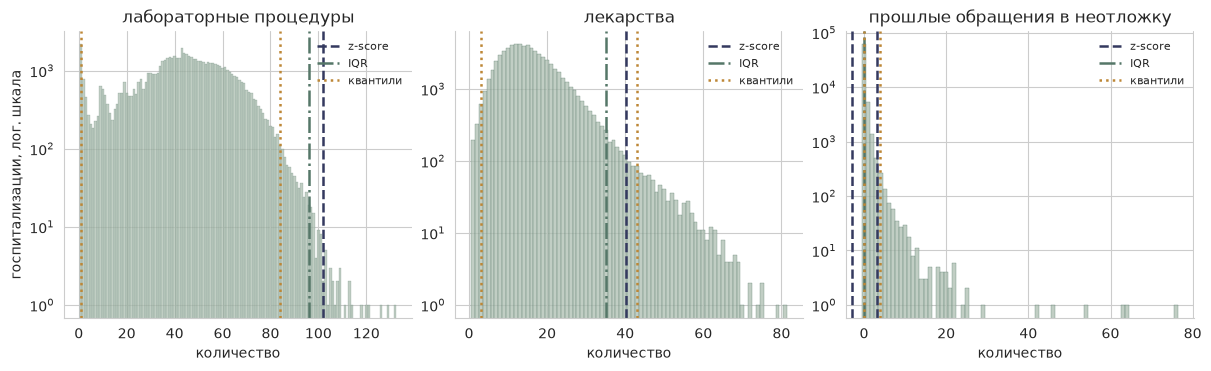

                      признак  правило  нижняя  верхняя  отмечено   доля
       лабораторные процедуры  z-score  -15.98   101.83        29  0.04%
       лабораторные процедуры      IQR   -8.00    96.00        83  0.12%
       лабораторные процедуры квантили    1.00    84.00       652  0.93%
                    лекарства  z-score   -8.33    40.29       927  1.33%
                    лекарства      IQR   -5.00    35.00      1722  2.46%
                    лекарства квантили    3.00    43.00      1185  1.69%
прошлые обращения в неотложку  z-score   -2.84     3.25       706  1.01%
прошлые обращения в неотложку      IQR    0.00     0.00      7846 11.22%
прошлые обращения в неотложку квантили    0.00     4.00       437  0.62%


In [26]:
rule_features = {**features, "number_emergency": "прошлые обращения в неотложку"}
rule_data = train[list(rule_features)]
means, stds = rule_data.mean(), rule_data.std(ddof=0)
assert stds.gt(0).all()
q1, q3 = rule_data.quantile(0.25), rule_data.quantile(0.75)
rule_iqr = q3 - q1
rule_colors = {"z-score": "#34395F", "IQR": "#557768", "квантили": "#BD8736"}
rule_styles = {"z-score": "--", "IQR": "-.", "квантили": ":"}
bounds = {
    "z-score": (means - 3 * stds, means + 3 * stds),
    "IQR": (q1 - 1.5 * rule_iqr, q3 + 1.5 * rule_iqr),
    "квантили": (low[list(rule_features)], high[list(rule_features)]),
}
natural_flags = {}
bound_rows = []
with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for (feature, label), ax in zip(rule_features.items(), axes, strict=True):
        values = rule_data[feature]
        sns.histplot(x=values, discrete=True, color="#ACBEB0", edgecolor="#557768", ax=ax)
        xmin, xmax = ax.get_xlim()
        ax.set_yscale("log")
        for method, (lower, upper) in bounds.items():
            lo, hi = lower[feature], upper[feature]
            flag = values.lt(lo) | values.gt(hi)
            natural_flags[feature, method] = flag
            bound_rows.append({
                "признак": label, "правило": method, "нижняя": lo, "верхняя": hi,
                "отмечено": flag.sum(), "доля": flag.mean(),
            })
            visible = [limit for limit in dict.fromkeys([lo, hi]) if xmin <= limit <= xmax]
            for i, limit in enumerate(visible):
                ax.axvline(limit, color=rule_colors[method], linestyle=rule_styles[method],
                           linewidth=1.8, label=method if i == 0 else None)
        ax.set(xlim=(xmin, xmax), title=label, xlabel="количество")
        ax.set_ylabel("госпитализации, лог. шкала" if ax is axes[0] else "")
        ax.legend(frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()

print(pd.DataFrame(bound_rows).round({"нижняя": 2, "верхняя": 2}).to_string(
    index=False, formatters={"доля": "{:.2%}".format},
))


#### Одинаковый бюджет и примеры расхождений

Для каждого признака берём по 1% строк на правило. z-score ранжирует по расстоянию от среднего в стандартных отклонениях. IQR ранжирует по выходу за границы, делённому на IQR. Квантили используют тот же балл выхода за границы, что и выше. Если положительных баллов меньше бюджета, остаток заполняют строки с нулевым баллом в фиксированном порядке. Показываем это отдельно. При нулевом IQR пропускаем рейтинг IQR.

«ничьи на отсечке» показывает все строки с баллом последней отобранной строки. «топ внутри границ» показывает, сколько отобранных строк не вышли за естественный порог правила.

In [27]:
budget_rows = []
examples_by_rule = []
for feature, label in rule_features.items():
    values = rule_data[feature]
    scores = {"z-score": ((values - means[feature]) / stds[feature]).abs()}
    method_scales = {"квантили": span[feature]}
    if rule_iqr[feature] > 0:
        method_scales["IQR"] = rule_iqr[feature]
    for method, scale in method_scales.items():
        lower, upper = bounds[method]
        scores[method] = pd.concat([lower[feature] - values, values - upper[feature]], axis=1).max(axis=1).clip(lower=0) / scale

    ranked = {method: top_rows(score) for method, score in scores.items()}
    membership = pd.DataFrame(
        {method: values.index.isin(rows) for method, rows in ranked.items()}, index=values.index,
    )
    assert membership.sum().eq(n_flagged).all()
    for method, rows in ranked.items():
        score = scores[method]
        cutoff = score.loc[rows].min()
        exclusive = rows.intersection(membership.index[membership.sum(axis=1).eq(1)])
        budget_rows.append({
            "признак": label, "правило": method,
            "совпали с квантилями": len(rows.intersection(ranked["квантили"])),
            "строк с баллом на границе": score.eq(cutoff).sum(),
            "в топе внутри естественных границ": (~natural_flags[feature, method].loc[rows]).sum(),
            "доля <30": train.loc[rows, "readmitted_30d"].mean(),
        })
        candidates = exclusive.intersection(values.index[natural_flags[feature, method]])
        example_rows = score.loc[candidates].nlargest(1).index
        if len(example_rows):
            examples_by_rule.append(train.loc[example_rows, ["encounter_id", "readmitted"]].assign(
                признак=label, правило=method, значение=values.loc[example_rows],
            ))
    if rule_iqr[feature] == 0:
        print(f"IQR для «{label}» равен нулю, рейтинг пропущен")

budget_table = pd.DataFrame(budget_rows).rename(columns={
    "совпали с квантилями": "совпало с квантилями",
    "строк с баллом на границе": "ничьи на отсечке",
    "в топе внутри естественных границ": "топ внутри границ",
})
budget_table["доля <30"] = budget_table["доля <30"].map("{:.1%}".format)
display(budget_table.set_index(["признак", "правило"]))
if examples_by_rule:
    display(pd.concat(examples_by_rule).reset_index(drop=True))
else:
    print("уникальных примеров за естественными границами нет")


IQR для «прошлые обращения в неотложку» равен нулю, рейтинг пропущен


совпало с квантилями  \
признак                       правило                          
лабораторные процедуры        z-score                    653   
                              квантили                   699   
                              IQR                        136   
лекарства                     z-score                    569   
                              квантили                   699   
                              IQR                        569   
прошлые обращения в неотложку z-score                    439   
                              квантили                   699   

                                        ничьи на отсечке  топ внутри границ  \
признак                       правило                                         
лабораторные процедуры        z-score               2199                670   
                              квантили             69292                 47   
                              IQR                  69861                616   
лекарства                     z-score                 84                  0   
                              квантили               259                  0   
                              IQR                     84                  0   
прошлые обращения в неотложку z-score                269                  0   
                              квантили             69507                262   

                                       доля <30  
признак                       правило            
лабораторные процедуры        z-score     12.4%  
                              квантили    12.7%  
                              IQR         11.6%  
лекарства                     z-score     12.3%  
                              квантили    11.2%  
                              IQR         12.3%  
прошлые обращения в неотложку z-score     29.6%  
                              квантили    22.2%

,encounter_id,readmitted,признак,правило,значение
0,139943934,>30,лекарства,квантили,1
1,249446148,>30,прошлые обращения в неотложку,z-score,4


**вывод.** Для анализов естественные пороги отметили 29 строк по z-score, 83 по IQR и 652 по квантилям. При бюджете в 699 строк в рейтинг попадают и записи внутри естественных границ, поэтому совпадение списков нужно читать вместе с числом таких записей. Для прошлых обращений в неотложку IQR равен нулю: правило отмечает все 7 846 строк, где число обращений больше нуля.

#### ECOD и влияние удаления аномалий

#### Что добавляет ECOD

ECOD из PyOD оценивает редкость значений по эмпирическим хвостам каждого признака и суммирует вклад признаков. Сравниваем верхний 1% его рейтинга на тех же семи числовых признаках и том же `train`. [Документация PyOD](https://pyod.readthedocs.io/en/latest/pyod.models.tabular.html#module-pyod.models.ecod)

квантили            269
Isolation Forest    487
LOF                 109
только ECOD: 152
доля <30 среди отмеченных ECOD: 27.3%
строк с баллом на границе ECOD: 1


,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_inpatient,number_emergency,number_outpatient,readmitted
0,280918776,9,90,6,38,1,2,0,>30
1,75723036,14,98,4,45,0,0,0,NO
2,228647100,11,97,6,53,0,0,0,>30
3,181279782,14,86,3,35,1,2,0,>30
4,41943612,14,89,6,51,0,0,0,NO


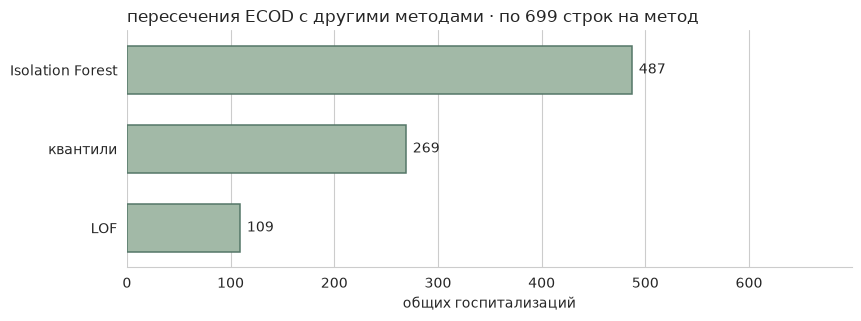

In [28]:
ecod = ECOD(contamination=0.01).fit(anomaly_features.to_numpy())
ecod_score = pd.Series(ecod.decision_scores_, index=train.index)
assert np.isfinite(ecod_score).all()
ecod_rows = top_rows(ecod_score)
detector_rows = {**selected_by, "ECOD": ecod_rows}
assert all(len(rows) == n_flagged for rows in detector_rows.values())

ecod_shared = pd.Series({
    method: len(ecod_rows.intersection(rows)) for method, rows in selected_by.items()
}, name="общих строк")
ecod_only = ecod_rows.difference(train.index[flags.any(axis=1)], sort=False)
print(ecod_shared.to_string())
print(f"только ECOD: {len(ecod_only):,}")
print(f"доля <30 среди отмеченных ECOD: {train.loc[ecod_rows, 'readmitted_30d'].mean():.1%}")
print(f"строк с баллом на границе ECOD: {ecod_score.eq(ecod_score.loc[ecod_rows].min()).sum()}")
display(train.loc[ecod_score.loc[ecod_only].nlargest(5).index,
                  ["encounter_id", *anomaly_columns, "readmitted"]].reset_index(drop=True))


with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(8.5, 3.1), layout="constrained")
    shared = ecod_shared.sort_values(ascending=False)
    sns.barplot(x=shared, y=shared.index, color="#A2B9A7", saturation=1,
                edgecolor="#557768", linewidth=1.1, width=0.6, ax=ax)
    ax.bar_label(ax.containers[0], padding=5)
    ax.set_title(f"пересечения ECOD с другими методами · по {n_flagged} строк на метод", loc="left")
    ax.set(xlabel="общих госпитализаций", ylabel=None, xlim=(0, n_flagged))
    sns.despine(ax=ax, left=True)
plt.show()


#### Помогает ли удаление строк

Сравниваем одну и ту же логистическую регрессию на полной обучающей выборке и после удаления одинакового числа строк. Для случайного контроля используем пять фиксированных seed. Предобработка заново обучается внутри каждого варианта, а оценка всегда идёт на одних и тех же пациентах из `validation`. Основная метрика: average precision. Итоговый тест оставляем для финальной оценки.

,строк убрали,ранних повторов убрали,average precision,ROC AUC,"изменение AP, п.п."
полный train,0,0,0.21909,0.65761,0.00000
квантили,699,181,0.21844,0.65760,-0.06462
Isolation Forest,699,193,0.21939,0.65844,0.02980
LOF,699,89,0.21789,0.65795,-0.11937
ECOD,699,191,0.21911,0.65828,0.00269
случайное удаление 42,699,76,0.21856,0.65791,-0.05237
случайное удаление 43,699,70,0.21909,0.65782,0.00020
случайное удаление 44,699,80,0.21915,0.65759,0.00591
случайное удаление 45,699,81,0.21929,0.65784,0.02038
случайное удаление 46,699,65,0.21887,0.65763,-0.02229


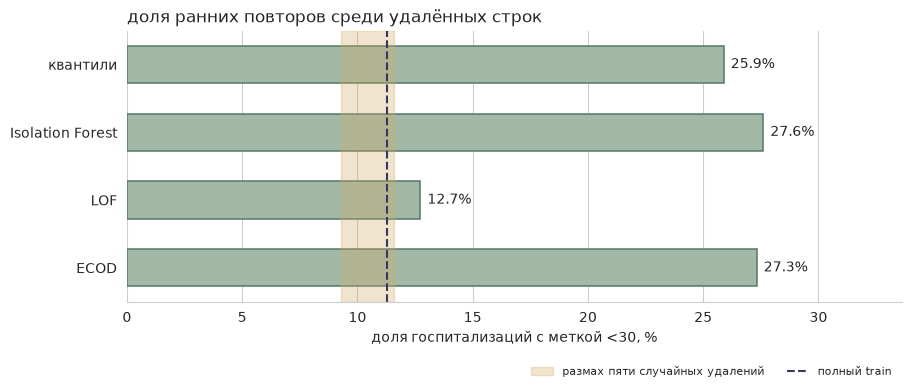

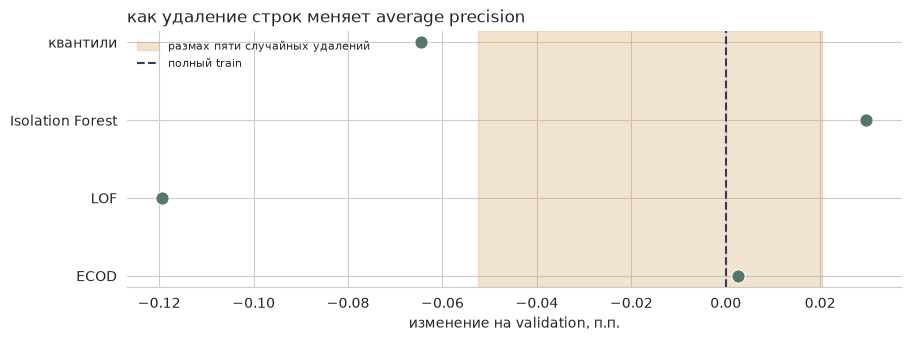

In [29]:
assert len(validation) == 15_172 and validation["patient_nbr"].nunique() == 10_566
assert not validation["patient_nbr"].isin(train["patient_nbr"]).any()

numeric = anomaly_columns
categorical = ["age", "admission_type_id", "admission_source_id", "discharge_disposition_id",
               "A1Cresult", "max_glu_serum"]
model_columns = numeric + categorical
target = "readmitted_30d"

def fit_and_evaluate(removed_rows):
    fit_data = train.drop(index=removed_rows)
    preprocessing = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])
    model = Pipeline([("preprocess", preprocessing),
                      ("logistic", LogisticRegression(max_iter=1000))])
    model.fit(fit_data[model_columns], fit_data[target])
    probability = model.predict_proba(validation[model_columns])[:, 1]
    return {
        "строк убрали": len(removed_rows),
        "ранних повторов убрали": train.loc[removed_rows, target].sum(),
        "average precision": average_precision_score(validation[target], probability),
        "ROC AUC": roc_auc_score(validation[target], probability),
    }

removals = {"полный train": train.index[:0], **detector_rows}
removals.update({
    f"случайное удаление {seed}": train.sample(n=n_flagged, random_state=seed).index
    for seed in range(42, 47)
})
assert all(len(rows) == n_flagged for name, rows in removals.items() if name != "полный train")
removal_results = pd.DataFrame({name: fit_and_evaluate(rows) for name, rows in removals.items()}).T
base_ap = removal_results.loc["полный train", "average precision"]
removal_results["изменение AP, п.п."] = (removal_results["average precision"] - base_ap) * 100
display(removal_results.round(5).astype({"строк убрали": int, "ранних повторов убрали": int}))

removed = removal_results.loc[removal_results["строк убрали"].gt(0)]
removed_rates = removed["ранних повторов убрали"].div(removed["строк убрали"]) * 100
detector_rates = removed_rates.loc[list(detector_rows)]
random_rates = removed_rates.loc[removed_rates.index.str.startswith("случайное")]

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
    sns.barplot(x=detector_rates, y=detector_rates.index, color="#A2B9A7", saturation=1,
                edgecolor="#557768", linewidth=1.1, width=0.55, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=5)
    ax.axvspan(random_rates.min(), random_rates.max(), color="#D6AB67", alpha=0.32,
               label="размах пяти случайных удалений")
    ax.axvline(train[target].mean() * 100, color="#34395F", linestyle="--", label="полный train")
    ax.set_title("доля ранних повторов среди удалённых строк", loc="left")
    ax.set(xlabel="доля госпитализаций с меткой <30, %", ylabel=None,
           xlim=(0, max(detector_rates.max(), random_rates.max()) + 6))
    ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1, -0.20), ncol=2)
    sns.despine(ax=ax, left=True)
plt.show()

random_deltas = removal_results.loc[removal_results.index.str.startswith("случайное"), "изменение AP, п.п."]
detector_deltas = removal_results.loc[list(detector_rows), "изменение AP, п.п."]
with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
    ax.axvspan(random_deltas.min(), random_deltas.max(), color="#D6AB67", alpha=0.32,
               label="размах пяти случайных удалений")
    ax.axvline(0, color="#34395F", linestyle="--", label="полный train")
    sns.scatterplot(x=detector_deltas, y=detector_deltas.index, color="#557768", s=92, ax=ax)
    ax.set_title("как удаление строк меняет average precision", loc="left")
    ax.set(xlabel="изменение на validation, п.п.", ylabel=None)
    ax.legend(frameon=False, fontsize=8)
    sns.despine(ax=ax, left=True)
plt.show()


**вывод.** ECOD выделил 152 госпитализации, которых не было в списках остальных методов. Удаление строк ECOD изменило AP на +0,003 п.п., что укладывается в разброс пяти случайных удалений. Isolation Forest дал наибольший прирост (+0,030 п.п.), а квантили и LOF снизили AP на 0,065 и 0,119 п.п. соответственно. На этой валидации прирост слишком мал, чтобы менять основную выборку. Случайный контроль показывает разброс пяти повторов, а не доверительный интервал.

### Дополнительные проверки выборки

Связи с целевой исследуем на `train`. Для проверки состава групповых фолдов используем только `train + validation`.

#### Какие поля доступны одновременно

Сравниваем сочетания четырёх полей. Доля в каждой ячейке считается внутри типа поступления. Коды `5`, `6` и `8` показываем отдельно, поскольку выше у них различалась частота измерения глюкозы.

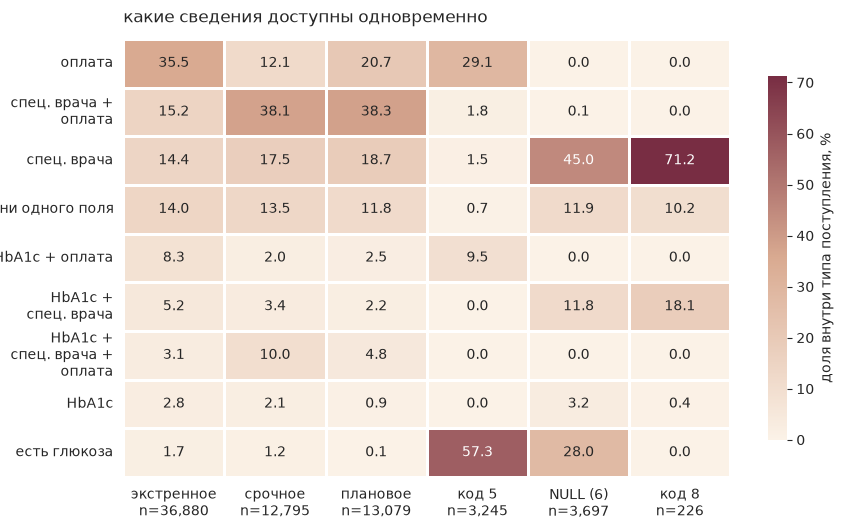

редкие типы поступления вне карты: 22 госпитализации


In [30]:
available = availability.rename(columns={
    "HbA1c измеряли": "HbA1c",
    "глюкозу измеряли": "глюкоза",
    "специальность указана": "специальность",
}).assign(оплата=train["payer_code"].notna())
coverage_admission_labels = {
    1: "экстренное", 2: "срочное", 3: "плановое",
    5: "код 5", 6: "NULL (6)", 8: "код 8",
}
coverage_admission_order = list(coverage_admission_labels.values())
admission = train["admission_type_id"].map(coverage_admission_labels).rename("поступление")
patterns = pd.Series(
    [" + ".join(available.columns[row]) or "ни одного поля" for row in available.to_numpy()],
    index=train.index, name="доступные поля",
)
no_glucose = ~available["глюкоза"]
common_patterns = patterns.loc[admission.notna() & no_glucose].value_counts().head(8).index
shown_patterns = patterns.where(patterns.isin(common_patterns), "прочие без глюкозы")
shown_patterns = shown_patterns.mask(~no_glucose, "есть глюкоза")
pattern_counts = pd.crosstab(shown_patterns, admission).reindex(
    index=[*common_patterns, "есть глюкоза", "прочие без глюкозы"],
    columns=coverage_admission_order, fill_value=0,
)
pattern_counts = pattern_counts.loc[pattern_counts.sum(axis=1).gt(0)]
assert pattern_counts.to_numpy().sum() == admission.notna().sum()
pattern_rates = pattern_counts.div(pattern_counts.sum(), axis=1) * 100
pattern_rates.columns = [
    f"{label}\nn={size:,}" for label, size in pattern_counts.sum().items()
]

pattern_rates.index = [
    (label.replace(" + ", " +\n") if len(label) > 18 else label).replace("специальность", "спец. врача")
    for label in pattern_counts.index
]

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(11, 6))
    fig.subplots_adjust(left=0.26, right=0.95, bottom=0.17, top=0.90)
    sns.heatmap(
        pattern_rates, cmap=sns.blend_palette(["#FBF2E7", "#D9AA91", "#782D43"], as_cmap=True),
        annot=True, fmt=".1f", vmin=0, linewidths=1, linecolor="white",
        cbar_kws={"label": "доля внутри типа поступления, %", "shrink": 0.83}, ax=ax,
    )
    ax.set_title("какие сведения доступны одновременно", loc="left", pad=12)
    ax.set(xlabel=None, ylabel=None)
    ax.tick_params(axis="both", labelrotation=0)
plt.show()

print(f"редкие типы поступления вне карты: {admission.isna().sum()} госпитализации")

#### Сколько полей доступно и как это связано с меткой

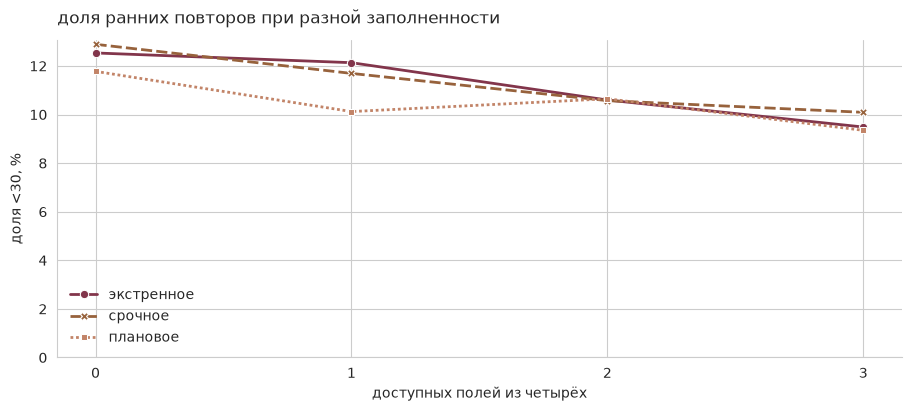

по всей обучающей выборке
                     n   rate
доступных полей              
0                8,903 12.55%
1               32,502 11.50%
2               24,809 10.79%
3                3,730 10.00%

число госпитализаций в группах графика
доступных полей       0        1        2       3
поступление                                      
экстренное       5146.0  19525.0  10965.0  1244.0
срочное          1730.0   4071.0   5666.0  1328.0
плановое         1537.0   5276.0   5635.0   631.0


In [31]:
coverage_size = available.sum(axis=1).rename("доступных полей")
outcome = train["readmitted_30d"]
coverage_summary = outcome.groupby(coverage_size).agg(n="size", rate="mean")
coverage_by_admission = outcome.groupby([admission, coverage_size]).agg(n="size", rate="mean")
coverage_groups = coverage_admission_order[:3]
coverage_plot = coverage_by_admission.loc[coverage_groups].reset_index()
coverage_plot["доля <30, %"] = coverage_plot["rate"] * 100
assert coverage_summary["n"].sum() == len(train)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    sns.lineplot(
        data=coverage_plot, x="доступных полей", y="доля <30, %",
        hue="поступление", style="поступление", markers=True,
        hue_order=coverage_groups, style_order=coverage_groups, palette=["#82354B", "#97623C", "#C28468"], linewidth=2, ax=ax,
    )
    ax.set_title("доля ранних повторов при разной заполненности", loc="left", pad=12)
    ax.set(xticks=sorted(coverage_size.unique()), xlabel="доступных полей из четырёх", ylim=(0, None))
    ax.legend(title=None, frameon=False)
    sns.despine(ax=ax)
plt.show()

print("по всей обучающей выборке")
print(coverage_summary.to_string(formatters={"n": "{:,}".format, "rate": "{:.2%}".format}))
print("\nчисло госпитализаций в группах графика")
print(coverage_by_admission["n"].unstack().loc[coverage_groups].to_string())

**Вывод.** При переходе от нуля доступных полей к трём доля `<30` ниже во всех трёх распространённых типах поступления. Для плановых госпитализаций линия не монотонна. Из 3 690 записей с измеренной глюкозой 2 894 относятся к кодам поступления `5` и `6`.

#### HbA1c и инсулин с равным весом пациентов

В обычном расчёте каждая госпитализация имеет вес 1. Во втором варианте каждой записи присваиваем вес, обратный числу строк пациента на `train`. Суммарный вес каждого пациента по всем его записям получается равным 1.

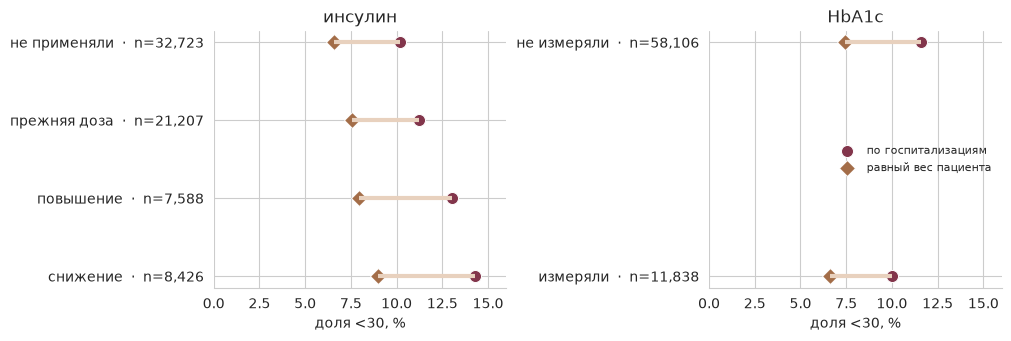

инсулин
                  n   rate weighted
insulin                            
не применяли  32723 10.19%    6.59%
прежняя доза  21207 11.22%    7.55%
повышение      7588 13.01%    7.93%
снижение       8426 14.31%    8.99%

HbA1c
                 n   rate weighted
HbA1c                             
не измеряли  58106 11.57%    7.41%
измеряли     11838 10.02%    6.63%



In [32]:
assert np.allclose(patient_weight.groupby(train["patient_nbr"]).sum(), 1)

weighted_reports = {}
medication_groups = [
    ("инсулин", train["insulin"].map({
        "No": "не применяли", "Steady": "прежняя доза", "Up": "повышение", "Down": "снижение",
    }), ["не применяли", "прежняя доза", "повышение", "снижение"]),
    ("HbA1c", available["HbA1c"].map({False: "не измеряли", True: "измеряли"}),
     ["не измеряли", "измеряли"]),
]
with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharex=True, layout="constrained")
    for (title, group, order), ax in zip(medication_groups, axes, strict=True):
        report = outcome.groupby(group).agg(n="size", rate="mean").reindex(order)
        report["weighted"] = (outcome * patient_weight).groupby(group).sum().div(
            patient_weight.groupby(group).sum()
        ).reindex(order)
        weighted_reports[title] = report
        y = np.arange(len(order))
        raw, weighted = report["rate"] * 100, report["weighted"] * 100
        ax.hlines(y, weighted, raw, color="#E8D1BE", linewidth=3)
        sns.scatterplot(x=raw, y=y, color="#82354B", s=75, label="по госпитализациям", ax=ax)
        sns.scatterplot(x=weighted, y=y, color="#A36D48", marker="D", s=65, label="равный вес пациента", ax=ax)
        ax.set_yticks(y, [f"{label}  ·  n={n:,}" for label, n in zip(order, report["n"], strict=True)])
        ax.invert_yaxis()
        ax.set(title=title, xlabel="доля <30, %", ylabel=None, xlim=(0, 16))
        sns.despine(ax=ax, left=True)
    axes[0].get_legend().remove()
    axes[1].legend(title=None, frameon=False, fontsize=8)
plt.show()

for title, report in weighted_reports.items():
    print(title)
    print(report.to_string(formatters={"rate": "{:.2%}".format, "weighted": "{:.2%}".format}), end="\n\n")

**Вывод.** Порядок четырёх групп по инсулину сохранился при равном весе пациентов. Разница между измеренным и неизмеренным HbA1c уменьшилась с 1,55 до 0,78 п.п. Оба сравнения описывают наблюдаемые группы.

#### Переводы и выписка в хоспис

Сравниваем исходный `train` с вариантами без хосписа, без переводов и без обеих групп. В узком исключаем коды `2`, `9` и `15`: перевод в другую краткосрочную больницу, оформление стационарного поступления в том же учреждении и перевод в койку длительного ухода внутри учреждения. В широком дополнительно исключаем другие явно указанные стационарные переводы (`5`, `22`, `23`, `27`, `28`, `29`, `30`). Сравнение проверяет чувствительность состава выборки. По CSV нельзя установить, какие переводы действительно продолжают тот же эпизод лечения.

In [33]:
disposition = train["discharge_disposition_id"]
narrow_codes = {2, 9, 15}
broad_codes = narrow_codes | {5, 22, 23, 27, 28, 29, 30}
assert broad_codes <= set(id_mapping.loc[id_mapping["field"].eq("discharge_disposition_id"), "code"])
is_hospice = disposition.isin([13, 14])
is_narrow_transfer = disposition.isin(narrow_codes)
assert not (is_hospice & is_narrow_transfer).any()

sample_masks = {
    "текущая выборка": pd.Series(True, index=train.index),
    "без хосписа": ~is_hospice,
    "без узкой группы переводов": ~is_narrow_transfer,
    "без расширенной группы переводов": ~disposition.isin(broad_codes),
    "без хосписа и узкой группы": ~(is_hospice | is_narrow_transfer),
}
sample_sensitivity = pd.DataFrame([
    {
        "вариант": label,
        "госпитализации": len(part),
        "пациенты": part["patient_nbr"].nunique(),
        "ранние повторы": part["readmitted_30d"].sum(),
        "доля <30": part["readmitted_30d"].mean(),
    }
    for label, mask in sample_masks.items()
    for part in [train.loc[mask]]
]).set_index("вариант")
sample_sensitivity["убрали строк"] = len(train) - sample_sensitivity["госпитализации"]
sample_sensitivity["убрали ранних повторов"] = (
    train["readmitted_30d"].sum() - sample_sensitivity["ранние повторы"]
)
assert sample_sensitivity.loc["без хосписа", "убрали строк"] == is_hospice.sum()
print(sample_sensitivity.to_string(formatters={"доля <30": "{:.2%}".format}))


                                  госпитализации  пациенты  ранние повторы доля <30  убрали строк  убрали ранних повторов
вариант                                                                                                                  
текущая выборка                            69944     49307            7907   11.30%             0                       0
без хосписа                                69395     48988            7878   11.35%           549                      29
без узкой группы переводов                 68367     48427            7639   11.17%          1577                     268
без расширенной группы переводов           65748     46992            7013   10.67%          4196                     894
без хосписа и узкой группы                 67818     48106            7610   11.22%          2126                     297


In [34]:
disposition_names = {
    1: "домой", 2: "другая краткосрочная больница", 5: "другой тип стационара",
    9: "стационар в том же учреждении", 15: "перевод внутри учреждения",
    22: "реабилитация", 23: "больница длительного ухода",
}
transfer_admission_codes = {4, 5, 6, 10, 22, 25, 26}
transfer_context = (
    train.loc[disposition.isin(disposition_names)]
    .assign(поступил_переводом=train["admission_source_id"].isin(transfer_admission_codes))
    .groupby("discharge_disposition_id")
    .agg(госпитализации=("encounter_id", "size"),
         медиана_дней=("time_in_hospital", "median"),
         доля_поступивших_переводом=("поступил_переводом", "mean"))
    .rename(index=disposition_names)
)
print(transfer_context.to_string(formatters={"доля_поступивших_переводом": "{:.1%}".format}))


                               госпитализации  медиана_дней доля_поступивших_переводом
discharge_disposition_id                                                              
домой                                   42003           3.0                       5.5%
другая краткосрочная больница            1519           3.0                       6.8%
другой тип стационара                     817           5.0                      11.1%
стационар в том же учреждении              15           4.0                       0.0%
перевод внутри учреждения                  43           6.0                       0.0%
реабилитация                             1416           5.0                       3.5%
больница длительного ухода                276           7.0                       5.8%


**Вывод.** Без хосписа доля `<30` меняется с 11,30% до 11,35%, а без узкой группы переводов составляет 11,17%. Широкое исключение переводов убирает 4 196 госпитализаций и 894 ранних повтора, снижая долю до 10,67%. Эти варианты сравнивают состав обучающей выборки.

#### Насколько сопоставим состав групповых фолдов

На данных разработки объединяем исходные `train` и `validation`. Делим их на пять фолдов по пациентам без стратификации по метке, чтобы увидеть естественные различия размера и доли `<30`. Это проверка состава выборок перед моделированием.

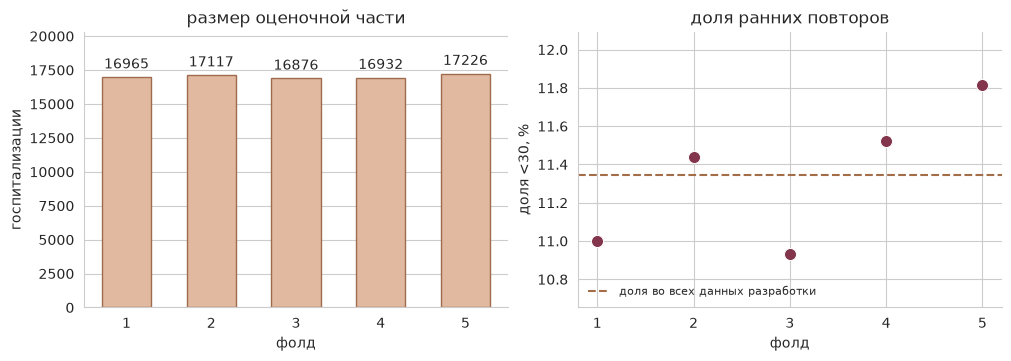

      пациенты  госпитализации доля <30, %
фолд                                      
1        11975           16965       11.00
2        11975           17117       11.44
3        11975           16876       10.93
4        11974           16932       11.52
5        11974           17226       11.81


In [35]:
assert not train["patient_nbr"].isin(validation["patient_nbr"]).any()
development = pd.concat([train, validation])
development_groups = development["patient_nbr"]

fold_rows = []
seen = set()
splitter = GroupKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (fit_idx, fold_val_idx) in enumerate(splitter.split(development, groups=development_groups), start=1):
    part = development.iloc[fold_val_idx]
    fold_patients = set(part["patient_nbr"])
    assert not fold_patients.intersection(development_groups.iloc[fit_idx])
    assert not seen.intersection(fold_patients)
    seen.update(fold_patients)
    fold_rows.append({
        "фолд": str(fold),
        "пациенты": len(fold_patients),
        "госпитализации": len(part),
        "доля <30, %": part["readmitted_30d"].mean() * 100,
    })
fold_summary = pd.DataFrame(fold_rows).set_index("фолд")
assert len(seen) == development_groups.nunique()
assert fold_summary["госпитализации"].sum() == len(development)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (size_ax, rate_ax) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
    sns.barplot(x=fold_summary.index, y=fold_summary["госпитализации"],
                color="#E0B9A0", edgecolor="#A06B4D", saturation=1, width=0.58, ax=size_ax)
    size_ax.bar_label(size_ax.containers[0], fmt="%d", padding=4)
    size_ax.set(title="размер оценочной части", xlabel="фолд", ylabel="госпитализации",
                ylim=(0, fold_summary["госпитализации"].max() * 1.18))

    rates = fold_summary["доля <30, %"]
    sns.scatterplot(x=fold_summary.index, y=rates, color="#82354B", s=75, ax=rate_ax)
    rate_ax.axhline(development["readmitted_30d"].mean() * 100, color="#A36D48",
                   linestyle="--", label="доля во всех данных разработки")
    rate_ax.set(title="доля ранних повторов", xlabel="фолд", ylabel="доля <30, %",
                ylim=(rates.min() - 0.28, rates.max() + 0.28))
    rate_ax.legend(loc="lower left", frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()

print(fold_summary.to_string(formatters={"доля <30, %": "{:.2f}".format}))


**Вывод.** В оценочной части каждого фолда около 12 тысяч пациентов и от 16 876 до 17 226 госпитализаций. Доля `<30` находится между 10,93% и 11,81%. Это показывает разброс состава фолдов. Разброс качества можно будет измерить после обучения моделей.